# Домашнее задание 2. Вариант NLP: NER - детекция в тексте

**Дедлайн:** вс 22.11.2026, 23:59

В ДЗ2 вы выбираете **один** вариант: CV (детекция объектов на YOLO) или NLP (этот ноутбук). Номера задач и баллы в вариантах совпадают. NER (named entity recognition) - это детекция в тексте: найти спаны, т.е. непрерывные куски из слов, и для каждого предсказать тип сущности. Вы берете предобученный энкодер с Hugging Face Hub, находите свой датасет, приводите разметку к формату модели, дообучаете, считаете метрики и разбираете ошибки.

- Заполняйте места с `# ваш код` и ячейки «**Ответ:**». Сигнатуры функций и открытые тесты не меняйте, свои ячейки добавлять можно. Открытые тесты проверяют часть контракта, при проверке будут и другие входы
- В ответах опирайтесь на свои числа: наблюдение, объяснение, ограничение вывода. Обычно хватает 2-4 предложений. Отсутствие ожидаемого эффекта - нормальный результат, если эксперимент корректный и вы это обсудили
- Свой код обязателен в 1.2 (параметры по блокам), 2.2 (конвертация разметки + тесты), 3.1 (словарный бейзлайн), 5.1 (категоризация ошибок). Для обучения и стандартных метрик можно `transformers` (`Trainer` или свой цикл) и `seqeval`
- `FAST_MODE = True` - отладка на маленьком подмножестве, весь ноутбук не дольше 5 минут на T4. Финальный прогон - с `FAST_MODE = False`, ориентир до ~1 часа на T4. Бонусы включаются через `BONUS_TASKS`, выключенные бонусы пропускаются, даже если их ячейки пустые
- Запуск: Colab (T4) или Kaggle (GPU T4, ноутбук сам берет одну карту). Зависимости ставит первая ячейка, пины те же, что в `requirements_nlp.txt`. Укажите устройство в ячейке ниже, время обучения возвращает ваш `train_ner` (4.1)
- Только открытые модели и данные. Лицензию модели и датасета укажите в 1.1 и 2.1
- Можно документацию, материалы курса и код семинаров - укажите источник
- Сдача как в ДЗ1: PR в свой публичный GitHub-репозиторий, ссылка на него - в Google-форму (ссылку на форму дадим отдельно). В PR - ноутбук с outputs и `artifacts/metrics.json` (пишется в 5.3, перед бонусами). Датасет (`data/`), `runs/` и веса моделей не кладите, достаточно кода скачивания; файл доразметки из 6.1 - кладите
- Для полной сдачи: Restart & Run All с `FAST_MODE = False`, сохранить outputs. Если сдаете частичное решение, перечислите нерешенные задачи в ячейке ниже и приложите то, что получилось. Ошибки не скрывайте: баллы ставятся по задачам, одна ошибка не обнуляет остальные
- ДЗ индивидуальное

| раздел | задачи | баллы |
|---|---|---|
| 1. Модель | 1.1 модель и ревизия · 1.2 архитектура | 4 |
| 2. Данные | 2.1 датасет · 2.2 формат разметки | 4 |
| 3. Бейзлайн | 3.1 бейзлайн до дообучения | 2 |
| 4. Дообучение | 4.1 обучение · 4.2 метрики | 6 |
| 5. Анализ | 5.1 разбор ошибок · 5.2 абляция · 5.3 выводы | 4 |
| 6*. Бонусы | 6.1 доразметка · 6.2 другая модель · 6.3 сдвиг · 6.4 экспорт и скорость · 6.5 пороги | до +4 из 5.5 |
| итого | | 20 + 4 |

Соответствие с CV-вариантом - задачи те же, меняется «геометрия»: вместо прямоугольника на картинке - отрезок из слов в предложении.

| CV (детекция на картинке) | NLP (NER в тексте) |
|---|---|
| бокс | спан: (начало, конец, тип) в индексах слов |
| класс объекта | тип сущности (PER, ORG, LOC, ...) |
| фон | тег `O` |
| VOC / COCO -> YOLO-формат | слова и спаны -> BIO-теги под сабворды токенизатора |
| backbone -> neck -> head | эмбеддинги -> слои энкодера -> голова token classification |
| mAP по IoU | F1 по сущностям (`seqeval`, спан засчитывается при точном совпадении границ и типа) |
| ошибка локализации (IoU 0.1-0.5) | ошибка границы спана (тип верный, спаны пересекаются) |
| ошибка класса | ошибка типа |
| пропуск / лишний бокс | пропуск / лишний спан |
| порог conf | порог уверенности спана |

Внутренности трансформера (attention, устройство слоя энкодера) - тема ДЗ3. Здесь энкодер рассматривается на уровне блоков.

Примерный план: первая неделя - разделы 1-3 (модель, датасет, разметка, бейзлайн), вторая - обучение, метрики, разбор ошибок, абляция и финальный прогон.

**Сведения о сдаче.** Укажите устройство (Colab T4 / Kaggle / свое), выбранные модель и датасет (ссылка и лицензия), бонусы, внешние источники и нерешенные задачи (если есть).

**Ответ:** Итоговый прогон выполнен в Google Colab на **NVIDIA Tesla T4** с `FAST_MODE = False`. Результаты сохранены в выводах ноутбука. Метрики основной части находятся в `artifacts/metrics.json`, метрики бонусов 6.2–6.5 — в `artifacts/bonus_metrics.json`.

- Энкодер — [google-bert/bert-base-cased, Apache 2.0](https://huggingface.co/google-bert/bert-base-cased/tree/cd5ef92a9fb2f889e972770a36d4ed042daf221e).
- Датасет — Few-NERD (`supervised`), английская Википедия с ручной разметкой, CC BY-SA 4.0. Подвыборка 6 000 / 1 000 / 1 000 предложений из готовых сплитов, восемь основных типов. [Данные и лицензия](https://huggingface.co/datasets/DFKI-SLT/few-nerd)
- Абляция — заморозка энкодера. Выполнены бонусы 6.2–6.5. Опциональный пункт 6.1 пропущен.
- Источники — шаблон ДЗ, [статья Few-NERD](https://aclanthology.org/2021.acl-long.248/), [статья BERT](https://aclanthology.org/N19-1423/), [Trainer](https://github.com/huggingface/transformers/blob/v5.22.1/src/transformers/trainer.py), [seqeval](https://github.com/chakki-works/seqeval), [DistilBERT cased](https://huggingface.co/distilbert/distilbert-base-cased/tree/6ea81172465e8b0ad3fddeed32b986cdcdcffcf0), [PyTorch dynamic quantization](https://docs.pytorch.org/docs/2.14/generated/torch.ao.quantization.quantize_dynamic.html).
- Для ручной сверки примеров в 5.1 — [издатель романа Алехо Карпентьера](https://us.macmillan.com/books/9780374537388/thekingdomofthisworld/) и [история Шверинского замка](https://www.landtag-mv.de/landtag/landtagssitz/geschichte-und-architektur/geschichte-des-schlosses).

In [1]:
# Зависимости (пины те же, что в requirements_nlp.txt). Запускайте эту ячейку первой, тогда перезапуск сессии не нужен
# Безвредный шум: строки ERROR от pip про bigframes / cudf / pyarrow на Kaggle и предупреждение про HF_TOKEN ниже (токен не нужен)
# Локально: сначала torch под свою платформу (https://pytorch.org/get-started/locally/)
%pip install -q "torch>=2.4" "transformers==5.22.1" "datasets==5.1.0" "accelerate==1.15.0" "seqeval==1.2.2" numpy matplotlib

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


In [2]:
import os
os.environ.setdefault('CUDA_VISIBLE_DEVICES', '0')   # одна GPU: на Kaggle T4 x2 иначе Trainer включит DataParallel (медленнее и хуже)
import collections
import copy
import json
import math
import random
import re
import time
from itertools import groupby
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import torch

import datasets
import transformers
from datasets import Dataset, DatasetDict, load_dataset
from huggingface_hub import HfApi
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score
from transformers import (AutoModelForTokenClassification, AutoTokenizer, DataCollatorForTokenClassification,
                          Trainer, TrainingArguments)

transformers.logging.set_verbosity_error()
plt.rcParams['figure.dpi'] = 100
plt.rcParams['font.size'] = 11

print(f'torch {torch.__version__}, transformers {transformers.__version__}, datasets {datasets.__version__}')
print(f'CUDA available: {torch.cuda.is_available()}')

from IPython.display import Markdown, display

torch 2.14.1+cu130, transformers 5.22.1, datasets 5.1.0
CUDA available: True


In [3]:
def get_device():
    if torch.cuda.is_available():
        return torch.device('cuda')
    if torch.backends.mps.is_available():
        return torch.device('mps')
    return torch.device('cpu')


def set_seed(seed=0):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    transformers.set_seed(seed)


device = get_device()
DEVICE_NAME = torch.cuda.get_device_name(0) if device.type == 'cuda' else device.type
set_seed(0)
print(device, DEVICE_NAME)

cuda Tesla T4


In [4]:
FAST_MODE = False  # True — быстрый прогон, False — итоговый эксперимент
BONUS_TASKS = {'6.2', '6.3', '6.4', '6.5'}
assert BONUS_TASKS <= {'6.1', '6.2', '6.3', '6.4', '6.5'}

SEED = 0
N_TRAIN = 512 if FAST_MODE else 6000
N_EVAL = 160 if FAST_MODE else 1000
EPOCHS = 1 if FAST_MODE else 3
MAX_LENGTH = 128
ARTIFACTS = Path('artifacts')
ARTIFACTS.mkdir(exist_ok=True)
RUN_TIMES = {}

---
# 1. Модель

## 1.1 Модель и ревизия (1.5 балла)

Выберите предобученный энкодер на Hugging Face Hub, подходящий под язык и домен вашего датасета. Модель на Hub - это git-репозиторий: владелец может перезалить веса, токенизатор или конфиг, и `main` начнет указывать на другую версию. Поэтому зафиксируйте `revision` - полный commit hash (40 символов). Его видно во вкладке «Files and versions» -> «History» или через `HfApi().model_info(MODEL_ID).sha`.

Ориентиры для выбора (не исчерпывающий список):
- русский: `cointegrated/rubert-tiny2` (29M параметров, быстрый), `DeepPavlov/rubert-base-cased` (~180M)
- многоязычные: `FacebookAI/xlm-roberta-base` (~280M), `google-bert/bert-base-multilingual-cased` (~180M), `distilbert/distilbert-base-multilingual-cased`
- английский: `google-bert/bert-base-cased`, `FacebookAI/roberta-base` (в 1.1 задайте `TOKENIZER_KWARGS = {'add_prefix_space': True}`), `microsoft/deberta-v3-small`
- биомедицина: `dmis-lab/biobert-base-cased-v1.2`

Нужен fast-токенизатор: `word_ids()`, без которого не выровнять метки по сабвордам, есть только у него. На T4 модель до ~300M параметров дообучается на датасете в десятки тысяч предложений за минуты - десятки минут.

Нужен базовый энкодер, а не модель, уже дообученная на NER: с ней 3.1 и 4.1 теряют смысл.

In [5]:
MODEL_ID = 'google-bert/bert-base-cased'
REVISION = 'cd5ef92a9fb2f889e972770a36d4ed042daf221e'
TOKENIZER_KWARGS = {}

In [6]:
assert MODEL_ID, 'укажите MODEL_ID'
assert re.fullmatch(r'[0-9a-f]{40}', REVISION or ''), 'REVISION - полный commit hash из 40 символов, а не main и не тег'
info = HfApi().model_info(MODEL_ID, revision=REVISION, files_metadata=True)
card = info.card_data.to_dict() if info.card_data else {}
weights = {s.rfilename: f'{s.size / 2**20:.0f} MB' for s in info.siblings if s.rfilename.endswith(('.safetensors', '.bin'))}
print(f'model:    {MODEL_ID}\nrevision: {info.sha}\nlicense:  {card.get("license")}\nlanguage: {card.get("language")}')
print(f'updated:  {info.last_modified}\nweights:  {weights}')

tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, revision=REVISION, **TOKENIZER_KWARGS)
assert tokenizer.is_fast, 'нужен fast-токенизатор: word_ids() есть только у него'
print(type(tokenizer).__name__, 'vocab size', tokenizer.vocab_size)
print(tokenizer.tokenize('i saw Lorde at Coachella last night'))

model:    google-bert/bert-base-cased
revision: cd5ef92a9fb2f889e972770a36d4ed042daf221e
license:  apache-2.0
language: en
updated:  2024-02-19 11:02:26+00:00
weights:  {'model.safetensors': '416 MB', 'pytorch_model.bin': '416 MB'}


config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

BertTokenizer vocab size 28996
['i', 'saw', 'Lord', '##e', 'at', 'Coach', '##ella', 'last', 'night']


**Вопрос.** Почему вы выбрали эту модель: язык и данные предобучения, размер и скорость, ожидаемое качество на NER, лицензия? Сравните с 1-2 альтернативами из списка выше: размер, язык, скорость, качество по карточке. Что может сломаться в вашем ноутбуке через полгода, если не фиксировать `revision`?

**Ответ:** `google-bert/bert-base-cased` — базовый английский энкодер с 12 слоями и примерно 108 млн параметров под Apache 2.0. BERT предобучен на BookCorpus и английской Википедии с задачами MLM и NSP. Сохранение регистра даёт полезный признак в энциклопедическом тексте, а контекст помогает отличать, например, название организации от географического имени. Голову для 17 BIO-тегов Few-NERD обучаем с нуля. Предобучение BERT также использовало Википедию, поэтому совпадение доменов помогает переносу, а пересечение исходных текстов полностью исключить нельзя. [Карточка модели](https://huggingface.co/google-bert/bert-base-cased) · [Статья BERT](https://aclanthology.org/N19-1423/)

`bert-base-uncased` имеет сопоставимый размер и вычислительную стоимость. Приведение к нижнему регистру сглаживает различия в написании, но убирает признак регистра. `distilbert-base-cased` сохраняет регистр и содержит шесть слоёв, поэтому требует меньше вычислений. В исходной статье полное дообучение BERT-Base с контекстом документа дало 92,4% entity F1 на тесте CoNLL-2003. Результат относится к новостному корпусу и служит ориентиром для выбора модели. Фиксация ревизии защищает эксперимент от обновления весов, конфигурации и соответствия WordPiece-токенов их ID. [BERT uncased](https://huggingface.co/google-bert/bert-base-uncased) · [DistilBERT cased](https://huggingface.co/distilbert/distilbert-base-cased) · [Статья BERT](https://aclanthology.org/N19-1423/)

## 1.2 Архитектура (2.5 балла)

Энкодер для token classification на уровне блоков:

1. **эмбеддинги** - сабворд -> вектор размера hidden (таблица `vocab_size x hidden`) + позиционные эмбеддинги (у DeBERTa их нет, позиции учитываются в attention) и type-эмбеддинги (у BERT-подобных), LayerNorm, dropout. Выход `(B, T, H)`
2. **N слоев энкодера** - одинаковые по форме блоки `(B, T, H) -> (B, T, H)`, в которых токены обмениваются информацией друг с другом. Устройство слоя (attention, FFN) - ДЗ3
3. **голова token classification** - dropout + `Linear(H, K)` к каждому токену независимо, K - число BIO-тегов. Выход - logits `(B, T, K)`
4. **сборка спанов** - argmax по тегам на первом сабворде каждого слова, затем BIO -> спаны (это уже не нейросеть, а ваш код из 2.2)

Ниже модель создается с головой на `N_DEMO_LABELS = 7` тегов (O + B/I для трех типов), под ваш датасет голову пересоздает `make_model` (3.1, 4.1).

1. Реализуйте `params_by_block(model)` - число параметров по блокам: `embeddings`, `encoder` (все слои), `head` (классификатор), `other` (все остальное: у BERT и RoBERTa для token classification здесь 0, у DeBERTa - `encoder.rel_embeddings` и общий `encoder.LayerNorm`) и `layers` - список по слоям энкодера. Сумма блоков должна совпасть с общим числом параметров
2. Прогоните dummy-вход `demo_texts` (батч из двух предложений, уже разбитых на слова) через токенизатор и модель с `output_hidden_states=True`, сохраните результат токенизатора в `enc`, выход модели в `out` и выведите формы: `input_ids`, `attention_mask`, все `hidden_states`, `logits`

In [7]:
N_DEMO_LABELS = 7
demo_model = AutoModelForTokenClassification.from_pretrained(MODEL_ID, revision=REVISION, num_labels=N_DEMO_LABELS)
cfg = demo_model.config
print({k: getattr(cfg, k, None) for k in ['model_type', 'vocab_size', 'hidden_size', 'num_hidden_layers',
                                          'num_attention_heads', 'intermediate_size', 'max_position_embeddings']})
for name, module in demo_model.named_children():
    print(f'{name:<12} {type(module).__name__}')

model.safetensors: reconstructing file:   0%|          |  0.00B /  436MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'model_type': 'bert', 'vocab_size': 28996, 'hidden_size': 768, 'num_hidden_layers': 12, 'num_attention_heads': 12, 'intermediate_size': 3072, 'max_position_embeddings': 512}
bert         BertModel
dropout      Dropout
classifier   Linear


In [8]:
def params_by_block(model):
    # -> {'embeddings': int, 'encoder': int, 'head': int, 'other': int, 'layers': [int, ...]}
    backbone = model.base_model
    embeddings = sum(p.numel() for p in backbone.embeddings.parameters())
    layers = [sum(p.numel() for p in layer.parameters()) for layer in backbone.encoder.layer]
    encoder = sum(layers)
    head = sum(p.numel() for p in model.classifier.parameters())
    total = sum(p.numel() for p in model.parameters())
    return dict(embeddings=embeddings, encoder=encoder, head=head,
                other=total - embeddings - encoder - head, layers=layers)

In [9]:
blocks = params_by_block(demo_model)
total = sum(p.numel() for p in demo_model.parameters())
assert sum(blocks[k] for k in ['embeddings', 'encoder', 'head', 'other']) == total
assert blocks['head'] == cfg.hidden_size * N_DEMO_LABELS + N_DEMO_LABELS
assert len(blocks['layers']) == cfg.num_hidden_layers and sum(blocks['layers']) == blocks['encoder'], \
    'encoder - сумма слоев, все вне слоев (например, rel_embeddings у DeBERTa) - в other'
assert blocks['embeddings'] >= cfg.vocab_size * cfg.hidden_size
for k in ['embeddings', 'encoder', 'head', 'other']:
    print(f'{k:<11}{blocks[k]:>13,}  {blocks[k] / total:6.1%}')
print(f'{"total":<11}{total:>13,}\nper layer: {blocks["layers"]}')

embeddings    22,665,216   21.0%
encoder       85,054,464   79.0%
head               5,383    0.0%
other                  0    0.0%
total        107,725,063
per layer: [7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872, 7087872]


In [10]:
demo_texts = [['We', 'saw', 'Lorde', 'at', 'Coachella', '.'],
              ['I', 'finally', 'played', 'Stardew', 'Valley', '!']]
enc = tokenizer(demo_texts, is_split_into_words=True, padding=True, return_tensors='pt')
demo_model.eval()
with torch.inference_mode():
    out = demo_model(**enc, output_hidden_states=True)

print('input_ids:', tuple(enc['input_ids'].shape))
print('attention_mask:', tuple(enc['attention_mask'].shape))
print('hidden_states:', [tuple(h.shape) for h in out.hidden_states])
print('logits:', tuple(out.logits.shape))
for i in range(len(demo_texts)):
    print(enc.tokens(i))

input_ids: (2, 10)
attention_mask: (2, 10)
hidden_states: [(2, 10, 768), (2, 10, 768), (2, 10, 768), (2, 10, 768), (2, 10, 768), (2, 10, 768), (2, 10, 768), (2, 10, 768), (2, 10, 768), (2, 10, 768), (2, 10, 768), (2, 10, 768), (2, 10, 768)]
logits: (2, 10, 7)
['[CLS]', 'We', 'saw', 'Lord', '##e', 'at', 'Coach', '##ella', '.', '[SEP]']
['[CLS]', 'I', 'finally', 'played', 'Star', '##de', '##w', 'Valley', '!', '[SEP]']


In [11]:
B, T = enc['input_ids'].shape
assert B == 2 and out.logits.shape == (B, T, N_DEMO_LABELS)
assert len(out.hidden_states) == cfg.num_hidden_layers + 1
assert all(h.shape == (B, T, cfg.hidden_size) for h in out.hidden_states)

# скорость прямого прохода: батч 32 предложения x 62 слова (сколько это сабвордов - см. вывод)
x = {k: v.to(device) for k, v in tokenizer([['word'] * 62] * 32, is_split_into_words=True, return_tensors='pt').items()}
demo_model.to(device).eval()
with torch.inference_mode():
    demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
    start = time.perf_counter()
    for _ in range(5):
        demo_model(**x)
    if device.type == 'cuda':
        torch.cuda.synchronize()
print(f'forward 32 x {x["input_ids"].shape[1]}: {(time.perf_counter() - start) / 5 * 1000:.1f} ms на {DEVICE_NAME}')
demo_model = demo_model.cpu()

forward 32 x 64: 103.4 ms на Tesla T4


**Вопрос.** Опишите путь входа по блокам с формами тензоров из вашего вывода. Какой блок содержит больше всего параметров и почему? В каком блоке токены обмениваются информацией, а где каждый токен обрабатывается независимо? Почему `T` в logits больше числа слов?

**Ответ:** Токенизатор формирует `input_ids` и `attention_mask` размера `(2, T)`. Сумма эмбеддингов сабвордов, позиций и сегментов даёт `(2, T, 768)`, такую же форму сохраняет каждый из 12 слоёв. Больше всего параметров в энкодере, поскольку каждый слой содержит свои проекции внимания и полносвязные преобразования. Контекст токенов меняется через self-attention, а линейная голова обрабатывает каждую позицию отдельно и выдаёт `(2, T, 7)` в демонстрации. В `T` учитываются сабворды, `[CLS]`, `[SEP]` и дополнение `[PAD]` до длины самого длинного примера в батче.

In [12]:
largest_block = max(('embeddings', 'encoder', 'head', 'other'), key=blocks.get)
display(Markdown(
    f'В демонстрационном батче **T = {T}**, логиты **{tuple(out.logits.shape)}**. '
    f'Самый большой блок — **{largest_block}**, **{blocks[largest_block]:,} из {total:,}** параметров '
    f'({blocks[largest_block] / total:.1%}). Голова на {N_DEMO_LABELS} меток содержит {blocks["head"]:,} параметров.'
))

В демонстрационном батче **T = 10**, логиты **(2, 10, 7)**. Самый большой блок — **encoder**, **85,054,464 из 107,725,063** параметров (79.0%). Голова на 7 меток содержит 5,383 параметров.

---
# 2. Данные

## 2.1 Датасет (1.5 балла)

Найдите датасет для NER на Hugging Face Hub или в другом открытом источнике, подходящий под вашу модель по языку. Опишите источник, лицензию, как размечали, типы сущностей, размер и сплиты; посчитайте статистику: число сущностей каждого типа по сплитам, распределение длин спанов (в словах), длины предложений.

**Нельзя брать WikiANN ru** (`unimelb-nlp/wikiann`, конфиг `ru`) - на нем ниже показан пример формата. Другие языки WikiANN брать можно.

Подсказки - датасеты, которые на момент выдачи загружаются текущей библиотекой `datasets` (проверено 31.10.2026, `datasets` 5.1). Библиотека больше не исполняет loading-скрипты, поэтому часть датасетов грузится из служебной ветки с parquet-версией - так, как написано в списке:

Русский:
- `Babelscape/wikineural` - WikiNEuRal, PER / ORG / LOC / MISC, 9 языков; для русского сплиты `train_ru`, `val_ru`, `test_ru`; CC BY-NC-SA 4.0
- `Babelscape/multinerd` - MultiNERD, 15 типов, 10 языков, колонка `lang` - отфильтруйте `ru`; CC BY-NC-SA 4.0
- `load_dataset('RCC-MSU/collection3', revision='refs/convert/parquet')` - Collection3, новости, PER / ORG / LOC, уже `tokens` + `ner_tags`
- `undefinedhorizons/nerus_lenta` - Nerus: новости Lenta.ru с автоматической разметкой PER / LOC / ORG, только `train` и очень большой - возьмите подмножество и сами отделите validation и test
- `gusevski/factrueval2016` - FactRuEval-2016, новости; вся разметка в одной вложенной колонке `data` - разобрать в предложения, слова и BIO
- `load_dataset('iluvvatar/RuNNE', revision='refs/convert/parquet')` и то же для `iluvvatar/NEREL` - новости, 29 типов, вложенные сущности, спаны по символам в тексте. Нужны разбиение на предложения и слова (целый текст длиннее `MAX_LENGTH = 128` сабвордов, хвост обрежется), BIO и правило для вложенных (например, оставить только внешние) - самая содержательная конвертация из списка

Другие языки:
- `unimelb-nlp/wikiann` - WikiANN, 176 языков (любой, кроме `ru`), PER / ORG / LOC
- `lhoestq/conll2003`, `tomaarsen/conll2003` или `load_dataset('eriktks/conll2003', revision='refs/convert/parquet')` - CoNLL-2003, английский, PER / ORG / LOC / MISC
- `DFKI-SLT/few-nerd`, конфиг `supervised` - Few-NERD, английский, 8 крупных и 66 мелких типов; теги в IO-схеме (без `B-` и `I-`) - переведите в BIO; CC BY-SA 4.0
- `load_dataset('tner/wnut2017', revision='refs/convert/parquet')` - WNUT-17, соцсети, редкие и новые сущности; имена тегов - в файле `dataset/label.json` репозитория

Биомедицина (английский):
- `load_dataset('ncbi/ncbi_disease', revision='refs/convert/parquet')` - NCBI-disease, один тип Disease
- `load_dataset('tner/bc5cdr', revision='refs/convert/parquet')` - BC5CDR, Chemical / Disease, теги в колонке `tags`: `{"O": 0, "B-Chemical": 1, "B-Disease": 2, "I-Disease": 3, "I-Chemical": 4}`

Если `load_dataset('<id>')` падает из-за loading-скрипта, берите ветку `revision='refs/convert/parquet'` (как в списке) или сырые файлы: `load_dataset('json', data_files='hf://datasets/<id>/<путь к файлу>')`. Датасеты из списка разрешены, лицензию укажите, как в карточке.

Если сплита validation или test нет, отделите их сами (`train_test_split` с фиксированным seed). Если датасет очень большой, возьмите подмножество и укажите это.

Контракт для остального ноутбука (после 2.2): `raw` - `DatasetDict` со сплитами `train`, `validation`, `test`, у каждого примера `tokens` (список слов) и `ner_tags` (список id тегов той же длины); `LABEL_NAMES` - список BIO-тегов, `LABEL_NAMES[i]` - тег с id `i`, тег `O` обязателен.

Если у `ner_tags` нет имен тегов (в `features` список чисел, а не `ClassLabel`; так у WikiNEuRal, MultiNERD и `lhoestq/conll2003`), составьте `LABEL_NAMES` вручную по карточке датасета. Например, у WikiNEuRal: `['O', 'B-PER', 'I-PER', 'B-ORG', 'I-ORG', 'B-LOC', 'I-LOC', 'B-MISC', 'I-MISC']`.

In [13]:
# Вымышленный пример формата Few-NERD. Значения IO указывают тип каждого слова.
example = {'tokens': ['We', 'visited', 'New', 'York', '.'],
           'ner_tags': ['O', 'O', 'location', 'location', 'O'],
           'fine_ner_tags': ['O', 'O', 'location-GPE', 'location-GPE', 'O']}
print(example)

{'tokens': ['We', 'visited', 'New', 'York', '.'], 'ner_tags': ['O', 'O', 'location', 'location', 'O'], 'fine_ner_tags': ['O', 'O', 'location-GPE', 'location-GPE', 'O']}


In [14]:
DATASET_ID, DATASET_CONFIG = 'DFKI-SLT/few-nerd', 'supervised'
DATASET_REVISION = '205f3e9c9f3577ea2561d43f2f62dc249ab92d5b'
fewnerd_source = load_dataset(DATASET_ID, DATASET_CONFIG, revision=DATASET_REVISION)
source_sizes = {split: len(ds) for split, ds in fewnerd_source.items()}
print('Исходные сплиты Few-NERD:', source_sizes)

train_features = fewnerd_source['train'].features
COARSE_NAMES = train_features['ner_tags'].feature.names
FINE_NAMES = train_features['fine_ner_tags'].feature.names
assert COARSE_NAMES == ['O', 'art', 'building', 'event', 'location', 'organization', 'other', 'person', 'product']
assert len(FINE_NAMES) == 67 and FINE_NAMES[0] == 'O'
FINE_TO_COARSE = [COARSE_NAMES.index(name.partition('-')[0]) for name in FINE_NAMES]
LABEL_NAMES = ['O'] + [f'{prefix}-{kind}' for kind in COARSE_NAMES[1:] for prefix in ('B', 'I')]

split_sizes = {'train': N_TRAIN, 'validation': N_EVAL, 'test': N_EVAL}
fewnerd_io = DatasetDict({
    split: fewnerd_source[split].shuffle(seed=SEED).select(range(size))
    for split, size in split_sizes.items()
})
print('Подвыборка:', {split: len(ds) for split, ds in fewnerd_io.items()})

README.md:   0%|          | 0.00/16.5k [00:00<?, ?B/s]

supervised/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 16.9MB            

supervised/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

supervised/validation-00000-of-00001.par(…): reconstructing file:   0%|          |  0.00B / 2.42MB            

supervised/validation-00000-of-00001.par(…): downloading bytes:           |  0.00B            

supervised/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 4.82MB            

supervised/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/131767 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/18824 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/37648 [00:00<?, ? examples/s]

Исходные сплиты Few-NERD: {'train': 131767, 'validation': 18824, 'test': 37648}
Подвыборка: {'train': 6000, 'validation': 1000, 'test': 1000}


In [15]:
def describe_split(ds):
    sentence_lengths = []
    lengths_by_type = {label[2:]: [] for label in LABEL_NAMES if label.startswith('B-')}
    for row in ds:
        sentence_lengths.append(len(row['tokens']))
        for start, end, kind in bio_to_spans([LABEL_NAMES[i] for i in row['ner_tags']]):
            lengths_by_type[kind].append(end - start)
    return sentence_lengths, lengths_by_type

**Вопрос.** Откуда датасет, под какой лицензией и как его размечали (вручную, автоматически, полуавтоматически)? Какие типы сущностей, сколько их по сплитам, какие типы редкие? Какие особенности данных (длина спанов, длина предложений, шум разметки) могут повлиять на обучение?

**Ответ:** Few-NERD — англоязычный корпус Википедии с ручной разметкой. Разметка иерархическая и содержит восемь основных и 66 детальных типов. Используем основные типы `art`, `building`, `event`, `location`, `organization`, `other`, `person`, `product`. Лицензия CC BY-SA 4.0. [Статья Few-NERD](https://aclanthology.org/2021.acl-long.248/) · [Карточка Hugging Face](https://huggingface.co/datasets/DFKI-SLT/few-nerd)

В конфигурации `supervised` три готовых сплита содержат 131 767 / 18 824 / 37 648 предложений. Для итогового эксперимента с seed 0 независимо выбираем 6 000 / 1 000 / 1 000 строк внутри этих сплитов. Подвыборка уменьшает время обучения. Редкие классы получают меньше обучающих примеров, а оценка длинных сущностей чувствительна к ошибкам хотя бы в одной границе. Частоты типов и распределения длин ниже считаются по фактической подвыборке. [Разбиение датасета](https://huggingface.co/datasets/DFKI-SLT/few-nerd#data-splits)

## 2.2 Формат разметки (2.5 балла)

Модель предсказывает тег для каждого **сабворда**, а разметка дана по **словам** (или спанами по символам). Нужны две конвертации и тесты к ним.

1. `bio_to_spans(tags)` - BIO-теги слов -> список спанов `(start, end, type)`, `end` не включается. `B-X` начинает спан, `I-X` продолжает спан того же типа, иначе начинает новый (так делает `seqeval` в режиме по умолчанию), `O` закрывает спан. Тип может содержать дефис (`B-art-film` -> `art-film`)
2. `spans_to_bio(spans, n_words)` - обратно: спаны -> BIO-теги длины `n_words`
3. `align_labels(word_labels, word_ids, b_to_i=None)` - метки слов -> метки сабвордов. `word_ids` - выход `tokenizer(...).word_ids(i)`: номер слова для каждого сабворда, `None` у спецтокенов. По умолчанию метка слова ставится на его первый сабворд, спецтокены и продолжения слова получают `-100` (cross-entropy их игнорирует). Если передан словарь `b_to_i` (id тега `B-X` -> id тега `I-X`), метку получают все сабворды слова, у продолжений `B-X` заменяется на `I-X` - это вариант для абляции 5.2

Если ваш датасет не в формате «слова + BIO» (спаны по символам, IO-теги, CoNLL-текст), сначала приведите его к контракту из 2.1 и проверьте конвертацию на примерах глазами. Если датасет уже в BIO, сделайте обратную конвертацию: BIO -> спаны в JSON (`data/<split>_spans.jsonl`), прочитайте файл обратно, сконвертируйте в BIO и проверьте, что получилось то же самое (если в исходнике есть `I-X` без `B-X`, дословно не совпадет: сравните спаны и посчитайте такие предложения).

In [16]:
def bio_to_spans(tags):
    # ['B-PER', 'I-PER', 'O', 'B-LOC'] -> [(0, 2, 'PER'), (3, 4, 'LOC')]
    spans = []
    start, active_type = 0, None
    for idx, tag in enumerate(tags):
        prefix, _, entity_type = tag.partition('-')
        if prefix == 'I' and active_type == entity_type:
            continue
        if active_type is not None:
            spans.append((start, idx, active_type))
        start = idx
        active_type = None if tag == 'O' else entity_type
    if active_type is not None:
        spans.append((start, len(tags), active_type))
    return spans


def spans_to_bio(spans, n_words):
    # [(0, 2, 'PER')], 3 -> ['B-PER', 'I-PER', 'O']
    tags = ['O'] * n_words
    for start, end, entity_type in spans:
        if not 0 <= start < end <= n_words:
            raise ValueError(f'Спан за пределами предложения: {(start, end, entity_type)}')
        if any(tag != 'O' for tag in tags[start:end]):
            raise ValueError(f'Пересекающиеся спаны: {(start, end, entity_type)}')
        tags[start:end] = [f'B-{entity_type}'] + [f'I-{entity_type}'] * (end - start - 1)
    return tags


def align_labels(word_labels, word_ids, b_to_i=None):
    # word_labels: id тегов слов; word_ids: номер слова для каждого сабворда (None - спецтокен) -> метки сабвордов
    aligned = []
    seen = set()
    for word_id in word_ids:
        if word_id is None:
            aligned.append(-100)
        elif word_id not in seen:
            aligned.append(word_labels[word_id])
            seen.add(word_id)
        elif b_to_i is not None:
            label = word_labels[word_id]
            aligned.append(b_to_i.get(label, label))
        else:
            aligned.append(-100)
    return aligned

In [17]:
tags = ['B-PER', 'I-PER', 'O', 'B-LOC', 'B-LOC', 'I-LOC', 'O', 'B-ORG']
assert bio_to_spans(tags) == [(0, 2, 'PER'), (3, 4, 'LOC'), (4, 6, 'LOC'), (7, 8, 'ORG')]
assert spans_to_bio(bio_to_spans(tags), len(tags)) == tags
assert bio_to_spans(['O', 'I-PER', 'I-PER', 'O']) == [(1, 3, 'PER')]       # I- без B- начинает спан
assert bio_to_spans(['B-PER', 'I-LOC', 'I-LOC']) == [(0, 1, 'PER'), (1, 3, 'LOC')]
assert bio_to_spans(['B-art-film', 'I-art-film', 'O']) == [(0, 2, 'art-film')]
assert bio_to_spans([]) == [] and bio_to_spans(['O'] * 3) == [] and spans_to_bio([], 2) == ['O', 'O']

rng = random.Random(0)
for _ in range(2000):   # туда-обратно на случайных спанах
    n, pos, spans = rng.randint(0, 15), 0, []
    while True:
        start = pos + rng.randint(0, 3)
        end = start + rng.randint(1, 4)
        if end > n:
            break
        spans.append((start, end, rng.choice(['PER', 'LOC', 'ORG'])))
        pos = end
    assert bio_to_spans(spans_to_bio(spans, n)) == spans, spans

word_ids = [None, 0, 0, 1, 2, 2, 2, None]
assert align_labels([1, 0, 3], word_ids) == [-100, 1, -100, 0, 3, -100, -100, -100]
assert align_labels([1, 0, 3], word_ids, b_to_i={1: 2, 3: 4}) == [-100, 1, 2, 0, 3, 4, 4, -100]
assert align_labels([2, 6], [None, 0, 0, 1, None], b_to_i={1: 2, 5: 6}) == [-100, 2, 2, 6, -100]
assert align_labels([5, 6, 0], [None, 0, None]) == [-100, 5, -100]        # обрезка по MAX_LENGTH
print('ok')

ok


In [18]:
def fewnerd_io_to_spans(coarse_ids, fine_ids):
    """Группирует одинаковые соседние IO-метки и записывает основные типы спанов."""
    start = 0
    spans = []
    for (coarse_id, fine_id), group in groupby(zip(coarse_ids, fine_ids, strict=True)):
        if FINE_TO_COARSE[fine_id] != coarse_id:
            raise ValueError(f'Несогласованные типы в слове {start}: {(coarse_id, fine_id)}')
        end = start + sum(1 for _ in group)
        if coarse_id != 0:
            spans.append((start, end, COARSE_NAMES[coarse_id]))
        start = end
    return spans


# Фильм и музыкальное произведение как соседние сущности одного основного типа.
art_id = COARSE_NAMES.index('art')
film_id, music_id = FINE_NAMES.index('art-film'), FINE_NAMES.index('art-music')
spans = fewnerd_io_to_spans([0, art_id, art_id, art_id, 0], [0, film_id, film_id, music_id, 0])
assert spans == [(1, 3, 'art'), (3, 4, 'art')]
assert spans_to_bio(spans, 5) == ['O', 'B-art', 'I-art', 'B-art', 'O']
assert fewnerd_io_to_spans([], []) == [] and fewnerd_io_to_spans([0, 0], [0, 0]) == []

encoding_ids = {tag: i for i, tag in enumerate(LABEL_NAMES)}
raw = DatasetDict()
boundaries_preserved = {}
for split, ds in fewnerd_io.items():
    rows = {'tokens': [], 'ner_tags': []}
    preserved = 0
    for ex in ds:
        words, coarse_ids, fine_ids = ex['tokens'], ex['ner_tags'], ex['fine_ner_tags']
        assert len(words) == len(coarse_ids) == len(fine_ids) > 0
        spans = fewnerd_io_to_spans(coarse_ids, fine_ids)
        bio_tags = spans_to_bio(spans, len(words))
        assert bio_to_spans(bio_tags) == spans
        assert [tag if tag == 'O' else tag[2:] for tag in bio_tags] == [COARSE_NAMES[i] for i in coarse_ids]
        preserved += sum(left[1] == right[0] and left[2] == right[2] for left, right in zip(spans, spans[1:]))
        rows['tokens'].append(words)
        rows['ner_tags'].append([encoding_ids[tag] for tag in bio_tags])
    raw[split] = Dataset.from_dict(rows)
    boundaries_preserved[split] = preserved
    print(f'{split}: преобразовано {len(rows["tokens"])} предложений, '
          f'сохранено границ между соседними спанами одного основного типа {preserved}')

example_index = next(i for i, ex in enumerate(fewnerd_io['train']) if any(ex['ner_tags']))
example_io, example_bio = fewnerd_io['train'][example_index], raw['train'][example_index]
print('Слово | исходный детальный тип | итоговый BIO')
for word, fine_id, label_id in zip(example_io['tokens'], example_io['fine_ner_tags'], example_bio['ner_tags']):
    print(f'{word:<18} {FINE_NAMES[fine_id]:<24} {LABEL_NAMES[label_id]}')

train: преобразовано 6000 предложений, сохранено границ между соседними спанами одного основного типа 14
validation: преобразовано 1000 предложений, сохранено границ между соседними спанами одного основного типа 1
test: преобразовано 1000 предложений, сохранено границ между соседними спанами одного основного типа 1
Слово | исходный детальный тип | итоговый BIO
Several            O                        O
bands              O                        O
of                 O                        O
Nez                organization-other       B-organization
Perce              organization-other       I-organization
actively           O                        O
resisted           O                        O
attempts           O                        O
to                 O                        O
restrict           O                        O
them               O                        O
to                 O                        O
reservation        O                        O
.            

In [19]:
span_dir = Path('data')
span_dir.mkdir(exist_ok=True)
bio_repairs = {}
for split, ds in raw.items():
    span_path = span_dir / f'{split}_spans.jsonl'
    with span_path.open('w', encoding='utf-8') as stream:
        for ex in ds:
            assert len(ex['tokens']) == len(ex['ner_tags']) > 0
            tags = [LABEL_NAMES[label] for label in ex['ner_tags']]
            record = {'tokens': ex['tokens'], 'spans': bio_to_spans(tags)}
            stream.write(json.dumps(record, ensure_ascii=False) + '\n')

    repairs = 0
    with span_path.open(encoding='utf-8') as stream:
        for ex, line in zip(ds, stream, strict=True):
            record = json.loads(line)
            assert record['tokens'] == ex['tokens']
            original = [LABEL_NAMES[label] for label in ex['ner_tags']]
            restored = spans_to_bio(record['spans'], len(record['tokens']))
            assert bio_to_spans(restored) == bio_to_spans(original)
            repairs += restored != original
    bio_repairs[split] = repairs
    print(f'{split}: {len(ds)} предложений, нормализация BIO потребовалась в {repairs}')

example_row = raw['train'][0]
example_tags = [LABEL_NAMES[i] for i in example_row['ner_tags']]
print(list(zip(example_row['tokens'], example_tags)))
print([(kind, ' '.join(example_row['tokens'][a:b])) for a, b, kind in bio_to_spans(example_tags)])

train: 6000 предложений, нормализация BIO потребовалась в 0
validation: 1000 предложений, нормализация BIO потребовалась в 0
test: 1000 предложений, нормализация BIO потребовалась в 0
[('Several', 'O'), ('bands', 'O'), ('of', 'O'), ('Nez', 'B-organization'), ('Perce', 'I-organization'), ('actively', 'O'), ('resisted', 'O'), ('attempts', 'O'), ('to', 'O'), ('restrict', 'O'), ('them', 'O'), ('to', 'O'), ('reservation', 'O'), ('.', 'O')]
[('organization', 'Nez Perce')]


In [20]:
assert isinstance(raw, DatasetDict) and isinstance(LABEL_NAMES, list), 'raw и LABEL_NAMES - из 2.1 (после конвертации в 2.2)'
assert {'train', 'validation', 'test'} <= set(raw), 'нужны сплиты train / validation / test'
assert {'tokens', 'ner_tags'} <= set(raw['train'].column_names)
assert 'O' in LABEL_NAMES and all(re.fullmatch(r'O|[BI]-.+', t) for t in LABEL_NAMES), LABEL_NAMES
label2id = {t: i for i, t in enumerate(LABEL_NAMES)}
id2label = dict(enumerate(LABEL_NAMES))
ENTITY_TYPES = sorted({t[2:] for t in LABEL_NAMES if t != 'O'})
B_TO_I = {label2id[t]: label2id['I-' + t[2:]] for t in LABEL_NAMES if t.startswith('B-') and 'I-' + t[2:] in label2id}


def subset(ds, n):
    return ds if n is None or n >= len(ds) else ds.shuffle(seed=SEED).select(range(n))


data = DatasetDict(train=subset(raw['train'], N_TRAIN), validation=subset(raw['validation'], N_EVAL),
                   test=subset(raw['test'], N_EVAL))


def tokenize_and_align(batch, tok=None, label_all_subwords=False):
    tok = tok or tokenizer
    enc = tok(batch['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    enc['labels'] = [align_labels(tags, enc.word_ids(i), B_TO_I if label_all_subwords else None)
                     for i, tags in enumerate(batch['ner_tags'])]
    return enc


tokenized = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names)
print(data)
print('ENTITY_TYPES', ENTITY_TYPES)

# проверка на реальных данных: метки первых сабвордов восстанавливают метки слов, спаны совпадают
n_at_limit = n_lost_words = n_checked = 0
for ex in data['train']:
    enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
    ids = enc.word_ids()
    labels = align_labels(ex['ner_tags'], ids)
    got = {w: l for w, l in zip(ids, labels) if l != -100}
    assert got == {w: ex['ner_tags'][w] for w in set(ids) - {None}}
    n_at_limit += len(enc['input_ids']) == MAX_LENGTH
    n_lost = len(ex['tokens']) - len(got)
    n_lost_words += n_lost
    if n_lost == 0:
        back = [LABEL_NAMES[got[w]] for w in range(len(ex['tokens']))]
        assert bio_to_spans(back) == bio_to_spans([LABEL_NAMES[i] for i in ex['ner_tags']])
        n_checked += 1
print(f'train: проверено {n_checked} предложений, достигли MAX_LENGTH {n_at_limit}, слов без сабвордов или за обрезкой {n_lost_words}')

ex = data['train'][0]
enc = tokenizer(ex['tokens'], is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
for sub, w, l in zip(enc.tokens(), enc.word_ids(), align_labels(ex['ner_tags'], enc.word_ids())):
    print(f'{sub:<16}{str(w):>5}  {LABEL_NAMES[l] if l != -100 else -100}')

Map:   0%|          | 0/6000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 6000
    })
    validation: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1000
    })
    test: Dataset({
        features: ['tokens', 'ner_tags'],
        num_rows: 1000
    })
})
ENTITY_TYPES ['art', 'building', 'event', 'location', 'organization', 'other', 'person', 'product']
train: проверено 5987 предложений, достигли MAX_LENGTH 13, слов без сабвордов или за обрезкой 303
[CLS]            None  -100
Several             0  O
bands               1  O
of                  2  O
N                   3  B-organization
##ez                3  -100
Per                 4  I-organization
##ce                4  -100
actively            5  O
resisted            6  O
attempts            7  O
to                  8  O
restrict            9  O
them               10  O
to                 11  O
reservation        12  O
.                  13  O
[SEP]            None  -100


| Сплит | Предложения | art | building | event | location | organization | other | person | product | Длина предложения, P50 / P95 / max |
|---|---:|---:|---:|---:|---:|---:|---:|---:|---:|---:|
| train | 6000 | 617 | 812 | 650 | 4279 | 2995 | 1574 | 3492 | 968 | 22 / 48 / 134 |
| validation | 1000 | 106 | 152 | 98 | 754 | 473 | 253 | 570 | 147 | 22 / 45 / 141 |
| test | 1000 | 98 | 117 | 116 | 721 | 486 | 250 | 536 | 176 | 22 / 47 / 86 |

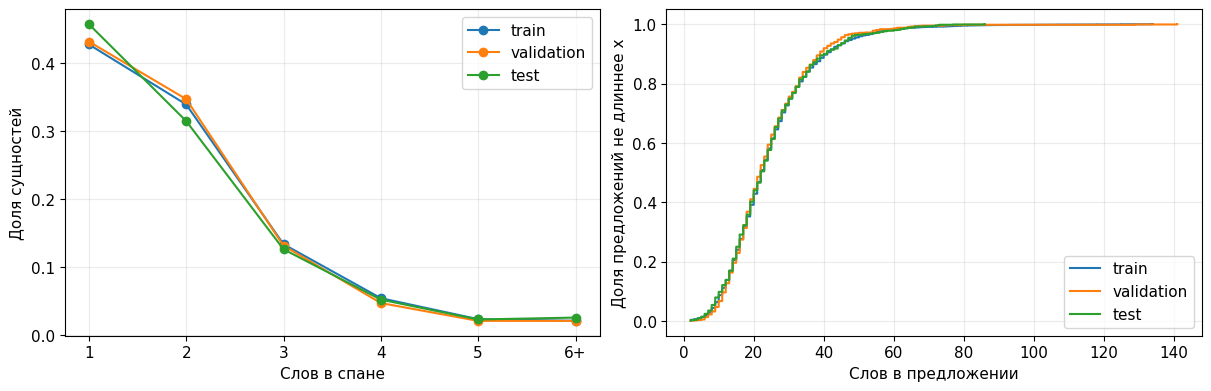

Самый редкий тип в train — **art** (617 спанов).

In [21]:
dataset_stats = {split: describe_split(ds) for split, ds in data.items()}
columns = ['Сплит', 'Предложения', *ENTITY_TYPES, 'Длина предложения, P50 / P95 / max']
rows = ['| ' + ' | '.join(columns) + ' |', '|---|' + '---:|' * (len(columns) - 1)]
for split, (sentences, by_type) in dataset_stats.items():
    counts = ' | '.join(str(len(by_type[kind])) for kind in ENTITY_TYPES)
    p50, p95 = np.percentile(sentences, [50, 95])
    rows.append(f'| {split} | {len(sentences)} | {counts} | {p50:g} / {p95:g} / {max(sentences)} |')
display(Markdown('\n'.join(rows)))

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), layout='constrained')
for split, (sentences, by_type) in dataset_stats.items():
    all_spans = [length for lengths in by_type.values() for length in lengths]
    span_buckets = collections.Counter(min(length, 6) for length in all_spans)
    axes[0].plot(range(1, 7), [span_buckets[i] / len(all_spans) for i in range(1, 7)], 'o-', label=split)
    sorted_lengths = np.sort(sentences)
    axes[1].step(sorted_lengths, np.arange(1, len(sentences) + 1) / len(sentences), where='post', label=split)
axes[0].set(xticks=list(range(1, 7)), xticklabels=['1', '2', '3', '4', '5', '6+'],
            xlabel='Слов в спане', ylabel='Доля сущностей')
axes[1].set(xlabel='Слов в предложении', ylabel='Доля предложений не длиннее x')
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
plt.show()

train_spans = dataset_stats['train'][1]
rare_kind = min(train_spans, key=lambda kind: len(train_spans[kind]))
display(Markdown(f'Самый редкий тип в train — **{rare_kind}** ({len(train_spans[rare_kind])} спанов).'))

**Вопрос.** Почему метка ставится только на первый сабворд, а остальным -100, и что -100 делает в loss? Сколько предложений обрезано по `MAX_LENGTH` и сколько слов не получили ни одного сабворда - как это повлияет на метрику? Какие проблемы нашлись при конвертации вашего датасета (невалидный BIO, пересекающиеся или вложенные спаны, расхождение токенизации)?

**Ответ:** Одна метка на слово даёт одинаковый вклад словам с одним и несколькими сабвордами. Значение `-100` исключает продолжения слов, спецтокены и паддинг из cross-entropy. При инференсе выбирается тег первого сабворда. Слова, которые выпали при токенизации, получают `O`, поэтому потеря части сущности может привести к пропуску или ошибке границы. В Few-NERD исходные IO-метки не содержат `B-`. Сначала находим спаны по переходам между детальными типами, затем присваиваем каждому спану основной тип. Так сохраняются границы между соседними сущностями одного основного типа. Две соседние сущности одного детального типа в исходной IO-разметке неразличимы.

In [22]:
truncation = {}
for split, ds in data.items():
    truncated, tail_words, omitted_words = 0, 0, 0
    for start in range(0, len(ds), 128):
        words_batch = ds[start:start + 128]['tokens']
        full = tokenizer(words_batch, is_split_into_words=True, truncation=False, verbose=False)
        short = tokenizer(words_batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH)
        for i, words in enumerate(words_batch):
            full_ids, short_ids = set(full.word_ids(i)) - {None}, set(short.word_ids(i)) - {None}
            truncated += len(full['input_ids'][i]) > MAX_LENGTH
            tail_words += len(full_ids - short_ids)
            omitted_words += len(words) - len(full_ids)
    truncation[split] = dict(truncated_sentences=truncated, dropped_tail_words=tail_words,
                             words_without_subwords=omitted_words)
    print(f'{split}: обрезано {truncated}/{len(ds)}, потеряно слов в хвосте {tail_words}, '
          f'слов без сабвордов до обрезки {omitted_words}, дополнительных нормализаций после IO → BIO {bio_repairs[split]}')

train: обрезано 13/6000, потеряно слов в хвосте 303, слов без сабвордов до обрезки 0, дополнительных нормализаций после IO → BIO 0
validation: обрезано 2/1000, потеряно слов в хвосте 89, слов без сабвордов до обрезки 0, дополнительных нормализаций после IO → BIO 0
test: обрезано 1/1000, потеряно слов в хвосте 2, слов без сабвордов до обрезки 0, дополнительных нормализаций после IO → BIO 0


---
# 3. Бейзлайн

## 3.1 Бейзлайн до дообучения (2 балла)

Метрики считаются по словам: тег слова - предсказание на его первом сабворде (функция `predict_word_tags` ниже). F1 по сущностям - `seqeval`: спан засчитывается, только если совпали обе границы и тип.

1. Реализуйте словарный бейзлайн: `fit_majority_tagger` запоминает для каждого слова из train самый частый его тег, `predict_majority` размечает предложение, незнакомые слова получают `O`
2. Посчитайте метрики бейзлайна и энкодера со случайно инициализированной головой (без дообучения) на validation

In [23]:
@torch.no_grad()
def predict_word_tags(model, tokens_list, tok=None, batch_size=64, return_probs=False, dev=None):
    # теги слов по первому сабворду; слова без сабвордов или за MAX_LENGTH получают 'O' (вероятность 1)
    tok, dev = tok or tokenizer, dev or device
    tokens_list = [list(ws) for ws in tokens_list]
    model.eval().to(dev)
    all_tags, all_probs = [], []
    for start in range(0, len(tokens_list), batch_size):
        batch = tokens_list[start:start + batch_size]
        enc = tok(batch, is_split_into_words=True, truncation=True, max_length=MAX_LENGTH, padding=True, return_tensors='pt')
        probs = model(**{k: v.to(dev) for k, v in enc.items()}).logits.float().softmax(-1).cpu()
        conf, best = probs.max(-1)
        for i, words in enumerate(batch):
            tags, word_conf, seen = ['O'] * len(words), [1.0] * len(words), set()
            for pos, w in enumerate(enc.word_ids(i)):
                if w is None or w in seen:
                    continue
                seen.add(w)
                tags[w], word_conf[w] = model.config.id2label[int(best[i, pos])], float(conf[i, pos])
            all_tags.append(tags)
            all_probs.append(word_conf)
    return (all_tags, all_probs) if return_probs else all_tags


def entity_scores(gold, pred):
    return dict(f1_micro=f1_score(gold, pred, average='micro', zero_division=0),
                f1_macro=f1_score(gold, pred, average='macro', zero_division=0),
                precision=precision_score(gold, pred, zero_division=0),
                recall=recall_score(gold, pred, zero_division=0))


def make_model(model_id=None, revision=None):
    return AutoModelForTokenClassification.from_pretrained(
        model_id or MODEL_ID, revision=revision or REVISION,
        num_labels=len(LABEL_NAMES), id2label=id2label, label2id=label2id)


val_tokens = [list(ws) for ws in data['validation']['tokens']]
val_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['validation']['ner_tags']]

In [24]:
def fit_majority_tagger(tokens_list, tags_list):
    counts = collections.defaultdict(collections.Counter)
    for words, tags in zip(tokens_list, tags_list, strict=True):
        for word, tag in zip(words, tags, strict=True):
            counts[word][tag] += 1
    return {word: counts_for_word.most_common(1)[0][0] for word, counts_for_word in counts.items()}


def predict_majority(tagger, words):
    return [tagger.get(word, 'O') for word in words]

In [25]:
toy_tokens = [['Анна', 'живет', 'в', 'Москве'], ['Москве', 'не', 'до', 'сна'], ['Анна', 'Каренина'], ['в', 'Москве']]
toy_tags = [['B-PER', 'O', 'O', 'B-LOC'], ['B-LOC', 'O', 'O', 'O'], ['B-PER', 'I-PER'], ['O', 'B-ORG']]
toy = fit_majority_tagger(toy_tokens, toy_tags)
assert toy['Москве'] == 'B-LOC' and toy['Анна'] == 'B-PER' and toy['Каренина'] == 'I-PER'
assert fit_majority_tagger([['Ленина']] * 4, [['B-LOC'], ['B-PER'], ['B-PER'], ['B-ORG']])['Ленина'] == 'B-PER'   # самый частый тег, а не первый или последний
assert predict_majority(toy, ['Анна', 'из', 'Москве']) == ['B-PER', 'O', 'B-LOC']
assert predict_majority(toy, []) == []


train_words = data['train']['tokens']
train_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['train']['ner_tags']]
tagger = fit_majority_tagger(train_words, train_gold)
majority_pred = [predict_majority(tagger, words) for words in val_tokens]
set_seed(SEED)
random_model = make_model()
random_pred = predict_word_tags(random_model, val_tokens)
del random_model
baseline = {'majority': entity_scores(val_gold, majority_pred),
            'random_head': entity_scores(val_gold, random_pred)}
for name, scores in baseline.items():
    print(name, {metric: round(value, 4) for metric, value in scores.items()})

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

majority {'f1_micro': np.float64(0.2036), 'f1_macro': np.float64(0.1263), 'precision': np.float64(0.2032), 'recall': np.float64(0.2041)}
random_head {'f1_micro': np.float64(0.0079), 'f1_macro': np.float64(0.0082), 'precision': np.float64(0.0045), 'recall': np.float64(0.0309)}


**Вопрос.** Какой F1 у словарного бейзлайна и почему он такой (вспомните, как размечен ваш датасет и как часто сущности повторяются)? Что предсказывает энкодер со случайной головой и почему его F1 близок к нулю, хотя энкодер предобучен?

**Ответ:** Словарь использует точное написание слова и его самый частый BIO-тег в train. Он может распознать знакомые части имени, но пропускает новые слова и не использует соседние токены для разрешения неоднозначности. В Few-NERD одно слово может быть частью разных названий или встречаться вне сущности. Словарь также путает начало и продолжение многословных имён, когда его частотный тег расходится с ролью слова в текущем спане. Случайная голова ещё не связывает контекстные представления BERT с типами и границами сущностей, поэтому совпадения целых спанов до обучения случайны.

In [26]:
entity_words = [word for words, tags in zip(val_tokens, val_gold)
                for word, tag in zip(words, tags) if tag != 'O']
covered = sum(word in tagger for word in entity_words)
random_tag_counts = collections.Counter(tag for tags in random_pred for tag in tags)
common_tag, common_n = random_tag_counts.most_common(1)[0]
word_coverage = covered / len(entity_words)
display(Markdown(
    f'На validation словарный F1 по сущностям равен **{baseline["majority"]["f1_micro"]:.3f}**. '
    f'В train встречались {word_coverage:.1%} слов из сущностей validation. '
    f'Случайная голова получила **{baseline["random_head"]["f1_micro"]:.3f}**. '
    f'Её самый частый тег `{common_tag}` занимает {common_n / random_tag_counts.total():.1%} слов.'
))

На validation словарный F1 по сущностям равен **0.204**. В train встречались 65.2% слов из сущностей validation. Случайная голова получила **0.008**. Её самый частый тег `I-person` занимает 35.5% слов.

---
# 4. Дообучение

## 4.1 Обучение (3 балла)

Реализуйте `train_ner`: дообучение модели на `tokenized['train']` с оценкой loss на `tokenized['validation']` по ходу обучения (не реже ~10 раз за обучение, чтобы получились кривые). Можно `Trainer` + `DataCollatorForTokenClassification` (он дополняет `labels` значением -100) или свой цикл. Параметр `freeze_encoder=True` замораживает все, кроме головы - он нужен для абляции 5.2. Функция возвращает `(history, seconds)`: `history` - список словарей с ключами `step` и `loss` (train) или `eval_loss`, как `trainer.state.log_history`.

Гиперпараметры выберите и обоснуйте: learning rate (у base-моделей обычно 2e-5 - 5e-5, маленьким моделям нужен больше), batch size, число эпох, warmup, weight decay, `fp16` на GPU.

В transformers 5 аргументы называются `eval_strategy` (не `evaluation_strategy`) и `processing_class` (не `tokenizer`), туториалы под версию 4 с ними падают. Чекпойнты не нужны: `save_strategy='no'`.

In [27]:
LR = 3e-5
BATCH_SIZE = 16


def train_ner(model, train_ds, eval_ds, epochs=EPOCHS, lr=LR, batch_size=BATCH_SIZE, freeze_encoder=False,
              tok=None, out_dir='runs/main'):
    # -> (history, seconds); history - список dict со 'step' и 'loss' или 'eval_loss'
    tok = tok or tokenizer
    model.base_model.requires_grad_(not freeze_encoder)
    if freeze_encoder:
        assert sum(p.numel() for p in model.parameters() if p.requires_grad) == params_by_block(model)['head']

    total_steps = math.ceil(len(train_ds) / batch_size) * epochs
    log_interval = max(1, total_steps // 10)
    use_fp16 = device.type == 'cuda'
    args = TrainingArguments(
        output_dir=out_dir,
        num_train_epochs=epochs,
        per_device_train_batch_size=batch_size,
        per_device_eval_batch_size=batch_size * 2,
        learning_rate=lr,
        weight_decay=0.01,
        warmup_steps=0.06,
        lr_scheduler_type='linear',
        optim='adamw_torch',
        logging_strategy='steps',
        logging_steps=log_interval,
        eval_strategy='steps',
        eval_steps=log_interval,
        save_strategy='no',
        fp16=use_fp16,
        prediction_loss_only=True,
        seed=SEED,
        data_seed=SEED,
        dataloader_pin_memory=use_fp16,
        report_to='none',
    )
    trainer = Trainer(
        model=model,
        args=args,
        train_dataset=train_ds,
        eval_dataset=eval_ds,
        processing_class=tok,
        data_collator=DataCollatorForTokenClassification(tok, pad_to_multiple_of=8 if use_fp16 else None),
    )
    start = time.perf_counter()
    trainer.train()
    if trainer.state.global_step % log_interval:
        trainer.evaluate()
    if device.type == 'cuda':
        torch.cuda.synchronize()
    return trainer.state.log_history, time.perf_counter() - start

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '1.213', 'grad_norm': '1.015', 'learning_rate': '2.886e-05', 'epoch': '0.2987'}
{'eval_loss': '0.3582', 'eval_runtime': '1.413', 'eval_samples_per_second': '707.5', 'eval_steps_per_second': '22.64', 'epoch': '0.2987'}
{'loss': '0.2942', 'grad_norm': '1.089', 'learning_rate': '2.569e-05', 'epoch': '0.5973'}
{'eval_loss': '0.2587', 'eval_runtime': '1.552', 'eval_samples_per_second': '644.4', 'eval_steps_per_second': '20.62', 'epoch': '0.5973'}
{'loss': '0.2314', 'grad_norm': '1.67', 'learning_rate': '2.251e-05', 'epoch': '0.896'}
{'eval_loss': '0.2323', 'eval_runtime': '1.42', 'eval_samples_per_second': '704.2', 'eval_steps_per_second': '22.54', 'epoch': '0.896'}
{'loss': '0.1906', 'grad_norm': '1.166', 'learning_rate': '1.933e-05', 'epoch': '1.195'}
{'eval_loss': '0.2335', 'eval_runtime': '1.289', 'eval_samples_per_second': '775.9', 'eval_steps_per_second': '24.83', 'epoch': '1.195'}
{'loss': '0.1733', 'grad_norm': '3.582', 'learning_rate': '1.615e-05', 'epoch': '1.493'}
{'eval

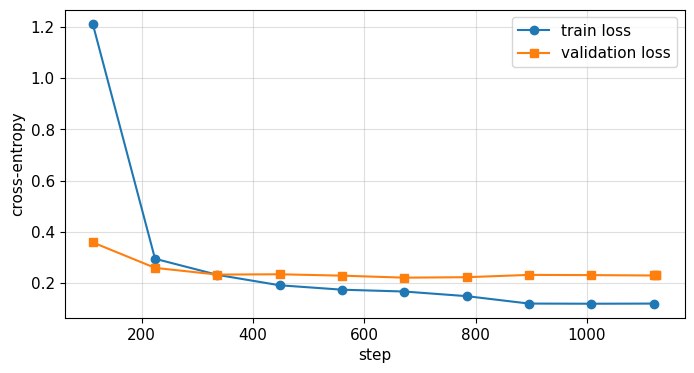

In [28]:
set_seed(SEED)
model = make_model()
history, train_seconds = train_ner(model, tokenized['train'], tokenized['validation'])
RUN_TIMES['train_main_sec'] = train_seconds
train_curve = [(h['step'], h['loss']) for h in history if 'loss' in h]
eval_curve = [(h['step'], h['eval_loss']) for h in history if 'eval_loss' in h]
assert len(train_curve) >= 2 and len(eval_curve) >= 2, 'логируйте train и eval loss по ходу обучения'
print(f'обучение: {train_seconds:.1f} c на {DEVICE_NAME}, {len(tokenized["train"])} предложений, {EPOCHS} эпох(а)')

plt.figure(figsize=(8, 4))
plt.plot(*zip(*train_curve), 'o-', label='train loss')
plt.plot(*zip(*eval_curve), 's-', label='validation loss')
plt.xlabel('step')
plt.ylabel('cross-entropy')
plt.legend()
plt.grid(True, alpha=0.4)
plt.show()

**Вопрос.** Почему выбраны такие гиперпараметры? Что видно на кривых: есть ли переобучение, нужно ли больше эпох? Сколько заняло обучение и на каком устройстве?

**Ответ:** Learning rate `3e-5` — стартовая настройка для полного дообучения BERT-base, чтобы аккуратно обновлять предобученные веса. Пакет из 16 примеров с динамическим паддингом ограничивает расход памяти. Три эпохи дают несколько проходов по выборке при умеренном бюджете. Первые 6% шагов плавно повышают LR, затем он линейно уменьшается. AdamW с weight decay `0.01` регуляризует веса, а FP16 на CUDA уменьшает расход памяти и ускоряет матричные операции.

In [29]:
best_step, best_eval_loss = min(eval_curve, key=lambda point: point[1])
last_step, last_eval_loss = eval_curve[-1]
if best_step == last_step:
    loss_interpretation = ('Минимум validation loss пришёлся на последнюю оценку. '
                           'По этой кривой полезно проверить дополнительную эпоху с оценкой entity F1 на validation.')
elif last_eval_loss > best_eval_loss * 1.05 and train_curve[-1][1] < train_curve[0][1]:
    loss_interpretation = ('После минимума validation loss вырос больше чем на 5%, хотя train loss в конце ниже начального. '
                           'Это признак возможного переобучения. Для выбора остановки стоит проверить entity F1 по эпохам.')
else:
    loss_interpretation = ('Минимум validation loss был раньше финального шага. '
                           'По этому прогону польза дополнительных эпох не установлена.')
display(Markdown(
    f'На **{DEVICE_NAME}** обучение с валидацией заняло **{train_seconds:.1f} с**. '
    f'Train loss изменился с {train_curve[0][1]:.4f} до {train_curve[-1][1]:.4f}. '
    f'Минимальный validation loss **{best_eval_loss:.4f}** получен на шаге {best_step}, '
    f'финальный — {last_eval_loss:.4f} на шаге {last_step}. {loss_interpretation}'
))

На **Tesla T4** обучение с валидацией заняло **166.3 с**. Train loss изменился с 1.2130 до 0.1190. Минимальный validation loss **0.2204** получен на шаге 672, финальный — 0.2288 на шаге 1125. Минимум validation loss был раньше финального шага. По этому прогону польза дополнительных эпох не установлена.

## 4.2 Метрики (3 балла)

1. Посчитайте на validation и test отчет `seqeval` по типам (P/R/F1, support), micro и macro F1
2. Реализуйте `token_f1(gold, pred)` - micro-F1 по словам: верное срабатывание - слово, у которого предсказанный тег не `O` и совпадает с истинным; тег `O` в precision и recall не участвует; если не-`O` слов нет ни в gold, ни в pred, функция возвращает 0.0
3. Сравните токенный F1 и F1 по сущностям и объясните разницу

In [30]:
def token_f1(gold, pred):
    # gold, pred: списки списков BIO-тегов -> micro-F1 по словам без тега O
    correct = predicted_entities = gold_entities = 0
    for gold_tags, pred_tags in zip(gold, pred, strict=True):
        for gold_tag, pred_tag in zip(gold_tags, pred_tags, strict=True):
            correct += gold_tag == pred_tag and gold_tag != 'O'
            predicted_entities += pred_tag != 'O'
            gold_entities += gold_tag != 'O'
    denominator = predicted_entities + gold_entities
    return 2 * correct / denominator if denominator else 0.0

In [31]:
g, p = [['B-PER', 'I-PER', 'O', 'B-LOC']], [['B-PER', 'O', 'O', 'B-LOC']]
assert abs(token_f1(g, p) - 0.8) < 1e-9                       # 2 верных слова из 2 предсказанных и 3 истинных
assert abs(f1_score(g, p) - 0.5) < 1e-9                       # а по сущностям верна одна из двух
assert token_f1([['O', 'O']], [['O', 'O']]) == 0.0 and token_f1(g, g) == 1.0


def evaluate_ner(gold_tags, predicted_tags):
    report = classification_report(gold_tags, predicted_tags, output_dict=True, zero_division=0)
    empty_row = {'precision': 0.0, 'recall': 0.0, 'f1-score': 0.0, 'support': 0}
    return dict(entity_scores(gold_tags, predicted_tags),
                token_f1=token_f1(gold_tags, predicted_tags),
                per_type={kind: report.get(kind, empty_row) for kind in ENTITY_TYPES})


test_tokens = [list(ws) for ws in data['test']['tokens']]
test_gold = [[LABEL_NAMES[i] for i in tags] for tags in data['test']['ner_tags']]
val_pred = predict_word_tags(model, val_tokens)
test_pred = predict_word_tags(model, test_tokens)
validation = evaluate_ner(val_gold, val_pred)
final = evaluate_ner(test_gold, test_pred)
for split, scores, targets, predictions in [('validation', validation, val_gold, val_pred),
                                             ('test', final, test_gold, test_pred)]:
    print(split)
    print(classification_report(targets, predictions, digits=4, zero_division=0))
    print(f'Entity micro-F1 {scores["f1_micro"]:.4f} | entity macro-F1 {scores["f1_macro"]:.4f} '
          f'| token micro-F1 {scores["token_f1"]:.4f}\n')

validation
              precision    recall  f1-score   support

         art     0.6019    0.6132    0.6075       106
    building     0.5966    0.6908    0.6402       152
       event     0.5546    0.6735    0.6083        98
    location     0.7720    0.8130    0.7920       754
organization     0.6130    0.6596    0.6354       473
       other     0.6752    0.6245    0.6489       253
      person     0.8604    0.9193    0.8889       570
     product     0.5723    0.6463    0.6070       147

   micro avg     0.7138    0.7591    0.7358      2553
   macro avg     0.6558    0.7050    0.6785      2553
weighted avg     0.7153    0.7591    0.7360      2553

Entity micro-F1 0.7358 | entity macro-F1 0.6785 | token micro-F1 0.7873

test
              precision    recall  f1-score   support

         art     0.6981    0.7551    0.7255        98
    building     0.5276    0.5726    0.5492       117
       event     0.4649    0.4569    0.4609       116
    location     0.7938    0.8488    0.8204

**Вопрос.** Какой тип сущностей распознается хуже всего и почему (частота, длина спанов, разнообразие)? Чем отличаются micro и macro F1 в вашем случае? Чем отличаются токенный F1 и F1 по сущностям в ваших числах и за счет чего (какой выше и почему)? Какой из них ближе к тому, что нужно пользователю NER?

**Ответ:** Micro-F1 суммирует совпадения, пропуски и ложные срабатывания по всем сущностям. Macro-F1 даёт одинаковый вес каждому типу. Токенная метрика даёт частичный кредит за отдельные правильные BIO-теги, даже если граница спана потеряна. Для использования NER ближе entity F1, поскольку потребителю нужен весь текст сущности вместе с её типом.

In [32]:
train_mentions = collections.defaultdict(set)
for words, tags in zip(train_words, train_gold):
    for start, end, kind in bio_to_spans(tags):
        train_mentions[kind].add(tuple(words[start:end]))

test_mentions = collections.defaultdict(list)
for words, tags in zip(test_tokens, test_gold):
    for start, end, kind in bio_to_spans(tags):
        test_mentions[kind].append(tuple(words[start:end]))

rows = ['| Тип | Спанов в train | Спанов в test | Средняя длина в test | Упоминания из test встречались в train |',
        '|---|---:|---:|---:|---:|']
for kind, mentions in sorted(test_mentions.items()):
    seen = sum(mention in train_mentions[kind] for mention in mentions) / len(mentions)
    rows.append(f'| {kind} | {len(train_spans[kind])} | {len(mentions)} | '
                f'{np.mean([len(mention) for mention in mentions]):.2f} | {seen:.1%} |')
display(Markdown('\n'.join(rows)))

worst_kind = min(test_mentions, key=lambda kind: final['per_type'][kind]['f1-score'])
worst_mentions = test_mentions[worst_kind]
worst_seen = sum(mention in train_mentions[worst_kind] for mention in worst_mentions) / len(worst_mentions)
display(Markdown(
    f'На test самый низкий F1 у **{worst_kind}** ({final["per_type"][worst_kind]["f1-score"]:.3f}). '
    f'У типа {len(train_spans[worst_kind])} спанов в train, а {1 - worst_seen:.1%} его тестовых упоминаний '
    f'не встречались там целиком с тем же типом. Длина и незнакомые названия могут влиять на результат, '
    f'но этих агрегатов недостаточно для вывода о причине. На test разность micro-F1 и macro-F1 равна '
    f'{100 * (final["f1_micro"] - final["f1_macro"]):+.2f} п. п., а разность токенного F1 и entity micro-F1 '
    f'равна {100 * (final["token_f1"] - final["f1_micro"]):+.2f} п. п.'
))

| Тип | Спанов в train | Спанов в test | Средняя длина в test | Упоминания из test встречались в train |
|---|---:|---:|---:|---:|
| art | 617 | 98 | 3.06 | 1.0% |
| building | 812 | 117 | 2.81 | 5.1% |
| event | 650 | 116 | 2.98 | 19.8% |
| location | 4279 | 721 | 1.42 | 44.7% |
| organization | 2995 | 486 | 2.56 | 10.1% |
| other | 1574 | 250 | 1.76 | 14.0% |
| person | 3492 | 536 | 1.72 | 8.8% |
| product | 968 | 176 | 2.02 | 3.4% |

На test самый низкий F1 у **event** (0.461). У типа 650 спанов в train, а 80.2% его тестовых упоминаний не встречались там целиком с тем же типом. Длина и незнакомые названия могут влиять на результат, но этих агрегатов недостаточно для вывода о причине. На test разность micro-F1 и macro-F1 равна +6.46 п. п., а разность токенного F1 и entity micro-F1 равна +5.45 п. п.

---
# 5. Анализ

## 5.1 Разбор ошибок (2 балла)

Аналог разбора ошибок детектора по IoU. Реализуйте `categorize_errors(gold_spans, pred_spans)`: каждый истинный спан получает ровно одну категорию, предсказанный спан, не пересекающийся ни с одним истинным, - категорию `spurious`. Возвращается список `(категория, истинный спан или None, предсказанный спан или None)`:

- `correct` - есть предсказанный спан с теми же границами и типом
- `boundary` - точного совпадения нет, но есть пересекающийся предсказанный спан того же типа (ошибка границы, аналог ошибки локализации)
- `type` - пересекающегося спана того же типа нет, но есть пересекающийся спан другого типа (ошибка типа, аналог ошибки класса)
- `missed` - ни один предсказанный спан не пересекается с истинным (пропуск)
- `spurious` - лишний спан (ложное срабатывание)

Посчитайте категории на validation, доли среди ошибок, покажите 5+ примеров ошибок разных категорий глазами (предложение, истинный и предсказанный спаны).

In [33]:
ERROR_CATEGORIES = ['correct', 'boundary', 'type', 'missed', 'spurious']


def categorize_errors(gold_spans, pred_spans):
    # -> [(категория, gold-спан или None, pred-спан или None), ...]
    def overlap(left, right):
        return max(0, min(left[1], right[1]) - max(left[0], right[0]))

    result = []
    for gold_span in gold_spans:
        overlaps = [span for span in pred_spans if overlap(gold_span, span)]
        same_type = [span for span in overlaps if span[2] == gold_span[2]]
        if gold_span in same_type:
            result.append(('correct', gold_span, gold_span))
        elif same_type:
            result.append(('boundary', gold_span, max(same_type, key=lambda span: overlap(gold_span, span))))
        elif overlaps:
            result.append(('type', gold_span, max(overlaps, key=lambda span: overlap(gold_span, span))))
        else:
            result.append(('missed', gold_span, None))
    result.extend(('spurious', None, span) for span in pred_spans
                  if not any(overlap(gold_span, span) for gold_span in gold_spans))
    return result

In [34]:
gold = [(0, 2, 'PER'), (4, 5, 'LOC'), (7, 9, 'ORG'), (11, 12, 'PER')]
pred = [(0, 2, 'PER'), (4, 6, 'LOC'), (7, 9, 'LOC'), (13, 14, 'ORG')]
res = categorize_errors(gold, pred)
assert collections.Counter(c for c, _, _ in res) == {'correct': 1, 'boundary': 1, 'type': 1, 'missed': 1, 'spurious': 1}
assert ('type', (7, 9, 'ORG'), (7, 9, 'LOC')) in res and ('spurious', None, (13, 14, 'ORG')) in res
assert ('boundary', (4, 5, 'LOC'), (4, 6, 'LOC')) in res and ('missed', (11, 12, 'PER'), None) in res
assert categorize_errors([], []) == [] and categorize_errors([], [(0, 1, 'PER')]) == [('spurious', None, (0, 1, 'PER'))]
assert [c for c, _, _ in categorize_errors([(0, 3, 'LOC')], [(1, 2, 'PER'), (2, 3, 'LOC')])] == ['boundary']
assert [c for c, _, _ in categorize_errors([(0, 2, 'LOC'), (2, 4, 'LOC')], [(0, 4, 'LOC')])] == ['boundary', 'boundary']
assert sorted(c for c, _, _ in categorize_errors([(0, 2, 'PER')], [(2, 3, 'PER')])) == ['missed', 'spurious']   # end не включается: спаны только соприкасаются


errors = dict.fromkeys(ERROR_CATEGORIES, 0)
examples_by_category = collections.defaultdict(list)
for words, gold_tags, pred_tags in zip(val_tokens, val_gold, val_pred, strict=True):
    for category, gold_span, pred_span in categorize_errors(bio_to_spans(gold_tags), bio_to_spans(pred_tags)):
        errors[category] += 1
        if category != 'correct':
            examples_by_category[category].append((words, gold_span, pred_span))

n_errors = sum(errors[kind] for kind in ERROR_CATEGORIES if kind != 'correct')
print(f'Точных совпадений {errors["correct"]}. Всего событий ошибок {n_errors}.')


def format_span(words, span):
    if span is None:
        return '—'
    start, end, kind = span
    return f'{kind} [{start}:{end}] «{" ".join(words[start:end])}»'


for category in ERROR_CATEGORIES[1:]:
    count = errors[category]
    print(f'\n{category}: {count} ({count / max(n_errors, 1):.1%} среди событий ошибок)')
    shown = set()
    for words, gold_span, pred_span in examples_by_category[category]:
        sentence = ' '.join(words)
        if sentence in shown:
            continue
        print(sentence)
        print(f'  gold {format_span(words, gold_span)}  |  pred {format_span(words, pred_span)}')
        shown.add(sentence)
        if len(shown) == 3:
            break

Точных совпадений 1938. Всего событий ошибок 809.

boundary: 234 (28.9% среди событий ошибок)
`` Puirt à beul `` has sometimes been used for dancing when no instruments were available .
  gold art [1:4] «Puirt à beul»  |  pred art [2:4] «à beul»
On duty , Columbo drives his own car , a French 1959 Peugeot 403 convertible equipped with a police radio .
  gold product [12:14] «Peugeot 403»  |  pred product [12:15] «Peugeot 403 convertible»
Jackson County is home to many attractions and recreation spots such as Flat Lick Falls , S-Tree Campground , Turkey Foot Campground , and the centermost trailhead ( located in the county seat , McKee ) of the historic Sheltowee Trace .
  gold location [16:18] «S-Tree Campground»  |  pred location [17:18] «Campground»

type: 287 (35.5% среди событий ошибок)
Regional competitions are held in most countries to select teams in the lead-up to the Festival , with winners of these going into the final round of the competitions at Cannes Lions .
  gold locati

**Вопрос.** Какая категория ошибок самая частая? Что общего у примеров в каждой категории? Какие ошибки - на самом деле ошибки разметки, а не модели? Что бы вы сделали, чтобы уменьшить самую частую категорию?

**Ответ:** Чаще всего встречалась ошибка типа `type` — 287 из 809 событий (35,5%). В `boundary` модель расширяла название описательным словом, как в `Peugeot 403 convertible`, или теряла часть имени, как в `S-Tree Campground`. В `type` модель относила `Italian` к месту вместо `other`, в `missed` целиком пропустила `The Wannadies`, а в `spurious` выделила год `1959` рядом с названием автомобиля. Чтобы сократить ошибки типа, сначала собрал бы матрицу путаницы пересекающихся спанов, затем добавил больше размеченных контекстов для самых частых пар.

Ручная сверка выявила вероятную ошибку эталона: Few-NERD присваивает `The Kingdom of This World` тип `event`, хотя в этом контексте речь о романе Алехо Карпентьера. Тип `art` у модели обоснован, и она отдельно ошиблась на границе, пропустив `The`. Ещё один вероятный пропуск эталона — имя `Paul Friedrich von Mecklenburg-Schwerin`: предсказание `person` в контексте титула великого герцога согласуется с источником. Эти наблюдения объясняют отдельные расхождения, а сохранённые метрики рассчитаны по исходной разметке. [Издатель романа](https://us.macmillan.com/books/9780374537388/thekingdomofthisworld/) · [Исторический источник](https://www.landtag-mv.de/landtag/landtagssitz/geschichte-und-architektur/geschichte-des-schlosses)

In [35]:
category_actions = {
    'boundary': 'добавить в train примеры многословных наименований и проверить точность границ по длине спана',
    'type': 'добавить контекстные примеры для часто путающихся типов и проверить матрицу путаницы',
    'missed': 'выделить пропуски новых упоминаний и хвостов после обрезки, затем добавить соответствующие обучающие примеры',
    'spurious': 'проверить ложные срабатывания на эталоне, а подтверждённые случаи добавить как трудные отрицательные примеры',
}
most_common_error = max(ERROR_CATEGORIES[1:], key=errors.get)
if n_errors:
    display(Markdown(
        f'Чаще всего встречается **{most_common_error}** — '
        f'{errors[most_common_error]} из {n_errors} событий ({errors[most_common_error] / n_errors:.1%}). '
        f'Чтобы сократить этот вид ошибок, можно {category_actions[most_common_error]}.'
    ))

possible_label_gaps = []
for words, _, pred_span in examples_by_category['spurious']:
    start, end, _ = pred_span
    surface = ' '.join(words[start:end])
    if any(c.isupper() for c in surface) and any(c.islower() for c in surface):
        possible_label_gaps.append((words, pred_span))
    if len(possible_label_gaps) == 3:
        break
if possible_label_gaps:
    print('Кандидаты на пропуск в ручной разметке Few-NERD. Сверка вручную нужна для подтверждения.')
    for words, pred_span in possible_label_gaps:
        print(f'  {format_span(words, pred_span)} — {" ".join(words)}')

Чаще всего встречается **type** — 287 из 809 событий (35.5%). Чтобы сократить этот вид ошибок, можно добавить контекстные примеры для часто путающихся типов и проверить матрицу путаницы.

Кандидаты на пропуск в ручной разметке Few-NERD. Сверка вручную нужна для подтверждения.
  person [3:4] «Küchen» — Its popularity helped Küchen get chosen for the court of Grand Duke Paul Friedrich von Mecklenburg-Schwerin .
  person [12:16] «Paul Friedrich von Mecklenburg-Schwerin» — Its popularity helped Küchen get chosen for the court of Grand Duke Paul Friedrich von Mecklenburg-Schwerin .
  event [14:15] «Theresienwiese» — The name `` Wiesentracht `` is given to Oktoberfest dirndls , referring to the Theresienwiese , where the Oktoberfest events occur .


## 5.2 Абляция (1 балл)

Один дополнительный эксперимент на выбор, все остальное как в 4.1:

- `'freeze'` - замороженный энкодер (учится только голова) vs полное дообучение. Сравните F1, время и число обучаемых параметров
- `'all_subwords'` - метка на все сабворды (`data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names, fn_kwargs=dict(label_all_subwords=True))`) vs только на первый. Оценка по-прежнему по словам через `predict_word_tags`

Результат положите в `ablation` - словарь с настройкой и метриками обоих вариантов.

In [36]:
ABLATION = 'freeze'
assert ABLATION in {'freeze', 'all_subwords'}
set_seed(SEED)
ablation_model = make_model()
if ABLATION == 'all_subwords':
    ablation_data = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                             fn_kwargs={'label_all_subwords': True})
else:
    ablation_data = tokenized
_, ablation_seconds = train_ner(ablation_model, ablation_data['train'], ablation_data['validation'],
                                freeze_encoder=ABLATION == 'freeze', out_dir=f'runs/{ABLATION}')
RUN_TIMES['train_ablation_sec'] = ablation_seconds
ablation_pred = predict_word_tags(ablation_model, val_tokens)
ablation = {
    'setting': ABLATION,
    'full': dict(entity_scores(val_gold, val_pred), train_time_sec=train_seconds,
                 trainable_params=sum(p.numel() for p in model.parameters() if p.requires_grad)),
    'variant': dict(entity_scores(val_gold, ablation_pred), train_time_sec=ablation_seconds,
                    trainable_params=sum(p.numel() for p in ablation_model.parameters() if p.requires_grad)),
}
del ablation_model
for name in ('full', 'variant'):
    print(name, ablation[name])

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

{'loss': '2.962', 'grad_norm': '7.719', 'learning_rate': '2.886e-05', 'epoch': '0.2987'}
{'eval_loss': '2.722', 'eval_runtime': '1.247', 'eval_samples_per_second': '801.8', 'eval_steps_per_second': '25.66', 'epoch': '0.2987'}
{'loss': '2.563', 'grad_norm': '6.564', 'learning_rate': '2.569e-05', 'epoch': '0.5973'}
{'eval_loss': '2.299', 'eval_runtime': '1.224', 'eval_samples_per_second': '816.7', 'eval_steps_per_second': '26.13', 'epoch': '0.5973'}
{'loss': '2.201', 'grad_norm': '5.918', 'learning_rate': '2.251e-05', 'epoch': '0.896'}
{'eval_loss': '1.968', 'eval_runtime': '1.217', 'eval_samples_per_second': '821.8', 'eval_steps_per_second': '26.3', 'epoch': '0.896'}
{'loss': '1.92', 'grad_norm': '5.344', 'learning_rate': '1.933e-05', 'epoch': '1.195'}
{'eval_loss': '1.721', 'eval_runtime': '1.287', 'eval_samples_per_second': '776.8', 'eval_steps_per_second': '24.86', 'epoch': '1.195'}
{'loss': '1.721', 'grad_norm': '4.418', 'learning_rate': '1.615e-05', 'epoch': '1.493'}
{'eval_loss': 

**Вопрос.** Насколько изменилась метрика и время? Чем вы объясняете результат? Что бы вы проверили следующим шагом, чтобы вывод был надежнее?

**Ответ:** Для обеих конфигураций использованы одинаковые данные, seed, начальные веса, LR, число эпох и способ оценки. При заморозке обновляется только линейная голова: исчезает обратный проход через энкодер, но прямой проход и регулярная валидация по-прежнему нужны. Чтобы оценить устойчивость разницы F1, можно повторить сравнение на нескольких seed и оценить разброс, учитывая, что оптимальный LR у головы может отличаться.

In [37]:
full_scores, variant_scores = ablation['full'], ablation['variant']
delta_f1 = variant_scores['f1_micro'] - full_scores['f1_micro']
delta_time = variant_scores['train_time_sec'] - full_scores['train_time_sec']
if ABLATION == 'freeze':
    ablation_explanation = (
        'Падение F1 согласуется с тем, что полное дообучение адаптирует контекстные признаки под BIO-теги.'
        if delta_f1 < 0 else
        'При выбранном бюджете замороженных признаков хватило, чтобы сравняться с полным дообучением или обойти его.'
    )
else:
    ablation_explanation = 'Разметка всех сабвордов увеличивает вклад слов, которые токенизатор разбивает на части.'
display(Markdown(
    f'При `{ABLATION}` изменение entity micro-F1 на validation составило **{100 * delta_f1:+.2f} п. п.** '
    f'({full_scores["f1_micro"]:.3f} → {variant_scores["f1_micro"]:.3f}). '
    f'Время изменилось на **{delta_time:+.1f} с** '
    f'({full_scores["train_time_sec"]:.1f} → {variant_scores["train_time_sec"]:.1f} с), '
    f'число обучаемых параметров — с {full_scores["trainable_params"]:,} до {variant_scores["trainable_params"]:,}. '
    f'{ablation_explanation}'
))

При `freeze` изменение entity micro-F1 на validation составило **-70.57 п. п.** (0.736 → 0.030). Время изменилось на **-123.0 с** (166.3 → 43.3 с), число обучаемых параметров — с 107,732,753 до 13,073. Падение F1 согласуется с тем, что полное дообучение адаптирует контекстные признаки под BIO-теги.

## 5.3 Выводы (1 балл)

5-8 предложений с числами: что сработало, что нет, главные ограничения (данные, разметка, модель, бюджет), что бы вы сделали дальше.

**Ответ:** Ниже выводы формируются из результатов текущего прогона, включая разницу с бейзлайнами и абляцию.

In [38]:
gain = validation['f1_micro'] - baseline['majority']['f1_micro']
error_summary = (f'На validation преобладали ошибки **{most_common_error}** '
                 f'({errors[most_common_error]} из {n_errors}).' if n_errors else
                 'На validation диагностика не нашла ошибок.')
next_step = category_actions[most_common_error] if n_errors else 'проверить модель на другом домене'
display(Markdown(
    f'На validation словарный бейзлайн дал **{baseline["majority"]["f1_micro"]:.3f}**, '
    f'а случайная голова — **{baseline["random_head"]["f1_micro"]:.3f}** entity micro-F1. '
    f'После обучения на {len(data["train"]):,} предложениях validation F1 составил '
    f'**{validation["f1_micro"]:.3f}**, изменение относительно словаря **{100 * gain:+.2f} п. п.** '
    f'На независимом test entity micro-F1 равен **{final["f1_micro"]:.3f}**, '
    f'а токенный micro-F1 — **{final["token_f1"]:.3f}**. '
    f'{error_summary} '
    f'Абляция `{ABLATION}` изменила validation F1 на **{100 * delta_f1:+.2f} п. п.**, '
    f'а время обучения — на **{delta_time:+.1f} с**. '
    'Выводы ограничены подвыборкой Few-NERD, восемью основными типами, '
    'неоднозначными границами исходной IO-разметки и одним seed. '
    f'Следующим шагом можно {next_step}.'
))

На validation словарный бейзлайн дал **0.204**, а случайная голова — **0.008** entity micro-F1. После обучения на 6,000 предложениях validation F1 составил **0.736**, изменение относительно словаря **+53.21 п. п.** На независимом test entity micro-F1 равен **0.735**, а токенный micro-F1 — **0.789**. На validation преобладали ошибки **type** (287 из 809). Абляция `freeze` изменила validation F1 на **-70.57 п. п.**, а время обучения — на **-123.0 с**. Выводы ограничены подвыборкой Few-NERD, восемью основными типами, неоднозначными границами исходной IO-разметки и одним seed. Следующим шагом можно добавить контекстные примеры для часто путающихся типов и проверить матрицу путаницы.

### Сохранение результатов

Ячейка сохраняет `artifacts/metrics.json`. Выполняется и в `FAST_MODE` для проверки формата, при финальном прогоне перезаписывается с `fast_mode: false`. Сдайте файл вместе с ноутбуком.

In [39]:
def json_ready(value):
    if isinstance(value, torch.Tensor):
        return json_ready(value.detach().cpu().tolist())
    if isinstance(value, np.ndarray):
        return json_ready(value.tolist())
    if isinstance(value, dict):
        return {str(k): json_ready(v) for k, v in value.items()}
    if isinstance(value, (tuple, list)):
        return [json_ready(v) for v in value]
    if isinstance(value, (float, np.floating)):
        return float(value) if math.isfinite(value) else None
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, Path):
        return value.as_posix()
    return value


metrics = dict(
    track='nlp', model=MODEL_ID, revision=REVISION,
    dataset=f'{DATASET_ID}/{DATASET_CONFIG}' if DATASET_CONFIG else str(DATASET_ID), classes=ENTITY_TYPES,
    n_train=len(data['train']), n_val=len(data['validation']), n_test=len(data['test']),
    params_total=sum(p.numel() for p in model.parameters()),
    dataset_revision=DATASET_REVISION, source_sizes=source_sizes,
    adjacent_boundaries_preserved=boundaries_preserved,
    seed=SEED, epochs=EPOCHS, max_length=MAX_LENGTH,
    baseline=baseline, validation=validation, final=final, ablation=ablation, errors=errors,
    truncation=truncation, bio_normalization=bio_repairs,
    device=DEVICE_NAME, train_time_sec=RUN_TIMES.get('train_main_sec'), fast_mode=FAST_MODE)
for key in ['f1_micro', 'f1_macro', 'precision', 'recall', 'token_f1', 'per_type']:
    assert key in final, f'в final нет {key}'
(ARTIFACTS / 'metrics.json').write_text(json.dumps(json_ready(metrics), ensure_ascii=False, indent=2), encoding='utf-8')
print(json.dumps(json_ready({k: v for k, v in metrics.items() if k not in ('final', 'baseline')}), ensure_ascii=False)[:600])
print('final F1 micro', round(final['f1_micro'], 4))

{"track": "nlp", "model": "google-bert/bert-base-cased", "revision": "cd5ef92a9fb2f889e972770a36d4ed042daf221e", "dataset": "DFKI-SLT/few-nerd/supervised", "classes": ["art", "building", "event", "location", "organization", "other", "person", "product"], "n_train": 6000, "n_val": 1000, "n_test": 1000, "params_total": 107732753, "dataset_revision": "205f3e9c9f3577ea2561d43f2f62dc249ab92d5b", "source_sizes": {"train": 131767, "validation": 18824, "test": 37648}, "adjacent_boundaries_preserved": {"train": 14, "validation": 1, "test": 1}, "seed": 0, "epochs": 3, "max_length": 128, "validation": {"
final F1 micro 0.7346


---
# 6\*. Бонусные задачи

Включаются через `BONUS_TASKS`, за бонусы суммарно - до 4 баллов из 5.5 предложенных.

## 6.1 Доразметка (1.5 балла)

Разметьте сами 50+ новых предложений (Label Studio, doccano или вручную в JSON): например, тексты из другого источника или трудные случаи из 5.1. Опишите инструкцию разметки, приведите разметку к контракту из 2.1, добавьте в train (или сделайте отдельный test) и покажите, как изменилась метрика. Файл с разметкой приложите к сдаче.

In [40]:
from itertools import groupby

bonus_results = {}


def save_bonus_result(task, result):
    bonus_results[task] = result
    payload = dict(model=MODEL_ID, revision=REVISION, dataset=DATASET_ID, config=DATASET_CONFIG,
                   device=DEVICE_NAME, fast_mode=FAST_MODE, seed=SEED, results=bonus_results)
    path = ARTIFACTS / 'bonus_metrics.json'
    temp = path.with_suffix('.tmp')
    temp.write_text(json.dumps(json_ready(payload), ensure_ascii=False, indent=2) + '\n', encoding='utf-8')
    temp.replace(path)


def prepare_benchmark_batch(words, tok, dev):
    enc = tok(words, is_split_into_words=True, padding=True, truncation=True,
              max_length=MAX_LENGTH, return_tensors='pt')
    return {name: tensor.to(dev) for name, tensor in enc.items()}


@torch.inference_mode()
def mean_forward_ms(ner_model, inputs, dev, warmup=5, repeats=20):
    """Среднее время forward на уже токенизированном батче."""
    ner_model.eval()
    synchronize = {'cuda': torch.cuda.synchronize, 'mps': torch.mps.synchronize}.get(dev.type)
    for _ in range(warmup):
        ner_model(**inputs)
    if synchronize:
        synchronize()
    start = time.perf_counter()
    for _ in range(repeats):
        ner_model(**inputs)
    if synchronize:
        synchronize()
    return (time.perf_counter() - start) * 1000 / repeats

In [41]:
if '6.1' in BONUS_TASKS:
    pass

**Вопрос.** Сколько и каких примеров вы разметили, сколько времени заняла разметка, как изменилась метрика и на каком сплите? Где вы сами сомневались в разметке?

**Ответ:** Опциональный пункт пропущен.

## 6.2 Другая модель (1 балл)

Сравните с другим энкодером (многоязычный vs одноязычный, base vs маленький) при том же протоколе - или zero-shot NER открытой LLM с Hugging Face против дообученного энкодера. Сравните F1, время обучения и инференса, размер.

In [42]:
if '6.2' in BONUS_TASKS:
    DISTIL_ID = 'distilbert/distilbert-base-cased'
    DISTIL_REVISION = '6ea81172465e8b0ad3fddeed32b986cdcdcffcf0'
    distil_tokenizer = AutoTokenizer.from_pretrained(DISTIL_ID, revision=DISTIL_REVISION, use_fast=True)
    assert distil_tokenizer.is_fast
    distil_data = data.map(tokenize_and_align, batched=True, remove_columns=data['train'].column_names,
                           fn_kwargs={'tok': distil_tokenizer})
    set_seed(SEED)
    distil_model = make_model(DISTIL_ID, DISTIL_REVISION)
    _, distil_sec = train_ner(distil_model, distil_data['train'], distil_data['validation'],
                              tok=distil_tokenizer, out_dir='runs/distilbert')
    distil_val = entity_scores(val_gold, predict_word_tags(distil_model, val_tokens, tok=distil_tokenizer))
    distil_test = entity_scores(test_gold, predict_word_tags(distil_model, test_tokens, tok=distil_tokenizer))

    comparison = {}
    benchmark_words = val_tokens[:16]
    for name, ner_model, tok, elapsed, val_report, test_report in (
        ('BERT-base', model, tokenizer, train_seconds, validation, final),
        ('DistilBERT', distil_model, distil_tokenizer, distil_sec, distil_val, distil_test),
    ):
        inputs = prepare_benchmark_batch(benchmark_words, tok, device)
        comparison[name] = dict(val_f1=val_report['f1_micro'], test_f1=test_report['f1_micro'],
                                train_time_sec=elapsed, forward_ms=mean_forward_ms(ner_model, inputs, device),
                                input_shape=list(inputs['input_ids'].shape),
                                parameters=sum(p.numel() for p in ner_model.parameters()),
                                weights_mib=sum(p.numel() * p.element_size() for p in ner_model.parameters()) / 2**20)
    del distil_model, ner_model
    save_bonus_result('6.2', dict(model=DISTIL_ID, revision=DISTIL_REVISION, license='Apache-2.0',
                                  device=DEVICE_NAME, warmup=5, repeats=20, comparison=comparison))
    table = ['| Энкодер | Val F1 | Test F1 | Обучение, с | Forward, мс | Параметры | Веса, МиБ |',
             '|---|---:|---:|---:|---:|---:|---:|']
    for name, row in comparison.items():
        table.append(f'| {name} | {row["val_f1"]:.4f} | {row["test_f1"]:.4f} | {row["train_time_sec"]:.1f} | '
                     f'{row["forward_ms"]:.2f} | {row["parameters"]:,} | {row["weights_mib"]:.1f} |')
    display(Markdown('\n'.join(table)))
    base_row, distil_row = comparison['BERT-base'], comparison['DistilBERT']
    display(Markdown(
        f'На **{DEVICE_NAME}** переход к DistilBERT изменил test F1 на '
        f'**{100 * (distil_row["test_f1"] - base_row["test_f1"]):+.2f} п. п.**, '
        f'время обучения на {distil_row["train_time_sec"] - base_row["train_time_sec"]:+.1f} с, '
        f'задержку батча на {distil_row["forward_ms"] - base_row["forward_ms"]:+.2f} мс. '
        'Размер указан для тензоров весов. Пиковая память при обучении также зависит от активаций и оптимизатора.'
    ))

config.json:   0%|          | 0.00/465 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/49.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/436k [00:00<?, ?B/s]

Map:   0%|          | 0/6000 [00:00<?, ? examples/s]

Map:   0%|          | 0/1000 [00:00<?, ? examples/s]

... (3 outputs left out)

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

{'loss': '1.24', 'grad_norm': '1.217', 'learning_rate': '2.886e-05', 'epoch': '0.2987'}
{'eval_loss': '0.3732', 'eval_runtime': '0.6004', 'eval_samples_per_second': '1666', 'eval_steps_per_second': '53.3', 'epoch': '0.2987'}
{'loss': '0.3012', 'grad_norm': '1.024', 'learning_rate': '2.569e-05', 'epoch': '0.5973'}
{'eval_loss': '0.2619', 'eval_runtime': '0.6797', 'eval_samples_per_second': '1471', 'eval_steps_per_second': '47.08', 'epoch': '0.5973'}
{'loss': '0.2402', 'grad_norm': '2.262', 'learning_rate': '2.251e-05', 'epoch': '0.896'}
{'eval_loss': '0.2377', 'eval_runtime': '0.6204', 'eval_samples_per_second': '1612', 'eval_steps_per_second': '51.58', 'epoch': '0.896'}
{'loss': '0.1995', 'grad_norm': '1.512', 'learning_rate': '1.933e-05', 'epoch': '1.195'}
{'eval_loss': '0.2318', 'eval_runtime': '0.6673', 'eval_samples_per_second': '1499', 'eval_steps_per_second': '47.95', 'epoch': '1.195'}
{'loss': '0.1752', 'grad_norm': '2.191', 'learning_rate': '1.615e-05', 'epoch': '1.493'}
{'eval

| Энкодер | Val F1 | Test F1 | Обучение, с | Forward, мс | Параметры | Веса, МиБ |
|---|---:|---:|---:|---:|---:|---:|
| BERT-base | 0.7358 | 0.7346 | 166.3 | 19.03 | 107,732,753 | 411.0 |
| DistilBERT | 0.7276 | 0.7161 | 71.9 | 9.60 | 65,203,985 | 248.7 |

На **Tesla T4** переход к DistilBERT изменил test F1 на **-1.84 п. п.**, время обучения на -94.4 с, задержку батча на -9.43 мс. Размер указан для тензоров весов. Пиковая память при обучении также зависит от активаций и оптимизатора.

**Вопрос.** Что лучше и какой ценой (время, память)? Как вы обеспечили честность сравнения?

**Ответ:** Сравниваем BERT-base-cased и DistilBERT-base-cased с шестью слоями. Для обоих одинаковы train, validation и test, seed, число эпох, learning rate, размер батча, длина входа и правило метки первого сабворда. Для каждого используется его WordPiece-токенизатор. Время инференса — среднее 20 прямых проходов по одним и тем же 16 предложениям на одном устройстве после пяти прогревочных проходов. Токенизация и перенос батча на устройство выполняются до замера. Сравнение F1, времени и веса параметров выводится в таблице эксперимента. [Модель DistilBERT и лицензия Apache 2.0](https://huggingface.co/distilbert/distilbert-base-cased/tree/6ea81172465e8b0ad3fddeed32b986cdcdcffcf0)

## 6.3 Устойчивость к сдвигу (1 балл)

Испортите validation и посмотрите на F1: опечатки, весь текст в нижнем или верхнем регистре, транслит, или другой домен (новости, соцсети, другой датасет с теми же типами). Метки при порче не меняются.

In [43]:
def swap_word_letters(words, seed, probability=0.15):
    rng = random.Random(seed)
    shifted = []
    for sentence in words:
        changed = []
        for word in sentence:
            positions = [i for i in range(1, len(word) - 2) if word[i] != word[i + 1]]
            if len(word) >= 5 and word.isalpha() and positions and rng.random() < probability:
                i = rng.choice(positions)
                word = word[:i] + word[i + 1] + word[i] + word[i + 2:]
            changed.append(word)
        shifted.append(changed)
    return shifted


def mean_subwords(words, tok):
    encoded = tok(words, is_split_into_words=True, add_special_tokens=False, truncation=False)
    return sum(len(ids) for ids in encoded['input_ids']) / sum(len(sentence) for sentence in words)


if '6.3' in BONUS_TASKS:
    variants = {'lowercase': [[word.lower() for word in sentence] for sentence in val_tokens],
                'uppercase': [[word.upper() for word in sentence] for sentence in val_tokens],
                'typos': swap_word_letters(val_tokens, SEED)}
    clean_f1 = validation['f1_micro']
    shift_results = {'clean': dict(f1_micro=clean_f1, mean_subwords=mean_subwords(val_tokens, tokenizer),
                                   changed_word_fraction=0.0, delta_f1=0.0)}
    for name, shifted in variants.items():
        assert [len(sentence) for sentence in shifted] == [len(sentence) for sentence in val_tokens]
        shift_scores = entity_scores(val_gold, predict_word_tags(model, shifted))
        n_changed = sum(old != new for a, b in zip(val_tokens, shifted, strict=True)
                        for old, new in zip(a, b, strict=True))
        shift_results[name] = dict(shift_scores, mean_subwords=mean_subwords(shifted, tokenizer),
                                   changed_word_fraction=n_changed / sum(map(len, val_tokens)),
                                   delta_f1=shift_scores['f1_micro'] - clean_f1)
    save_bonus_result('6.3', dict(split='validation', n_sentences=len(val_tokens),
                                  typo_probability=0.15, conditions=shift_results))
    table = ['| Условие | Entity micro-F1 | Δ F1, п. п. | Изменилось слов | Сабвордов на слово |',
             '|---|---:|---:|---:|---:|']
    for name, row in shift_results.items():
        table.append(f'| {name} | {row["f1_micro"]:.4f} | {100 * row["delta_f1"]:+.2f} | '
                     f'{row["changed_word_fraction"]:.1%} | {row["mean_subwords"]:.2f} |')
    display(Markdown('\n'.join(table)))
    worst = min(variants, key=lambda name: shift_results[name]['f1_micro'])
    row = shift_results[worst]
    mechanism = ('Перестановки букв меняют написание и могут разбить знакомое слово на другие сабворды.'
                 if worst == 'typos' else 'Изменение регистра убирает привычный признак начала имени для cased BERT.')
    display(Markdown(
        f'Самый низкий F1 получен при **{worst}**, изменение к чистому validation '
        f'**{100 * row["delta_f1"]:+.2f} п. п.**. {mechanism} '
        f'В среднем сабвордов на слово стало {row["mean_subwords"]:.2f} '
        f'при {shift_results["clean"]["mean_subwords"]:.2f} на исходном тексте.'
    ))

| Условие | Entity micro-F1 | Δ F1, п. п. | Изменилось слов | Сабвордов на слово |
|---|---:|---:|---:|---:|
| clean | 0.7358 | +0.00 | 0.0% | 1.23 |
| lowercase | 0.3323 | -40.34 | 24.1% | 1.33 |
| uppercase | 0.0346 | -70.11 | 82.5% | 2.69 |
| typos | 0.7146 | -2.11 | 6.0% | 1.34 |

Самый низкий F1 получен при **uppercase**, изменение к чистому validation **-70.11 п. п.**. Изменение регистра убирает привычный признак начала имени для cased BERT. В среднем сабвордов на слово стало 2.69 при 1.23 на исходном тексте.

**Вопрос.** Какая порча сильнее всего роняет F1 и почему (вспомните, как токенизатор режет слова и какие признаки сущности есть в тексте)?

**Ответ:** Для одних и тех же предложений validation проверяем нижний регистр, верхний регистр и опечатки. Опечатка — перестановка двух соседних разных букв внутри слова, с вероятностью 15% для подходящего слова. Seed фиксирован. Границы слов и эталонные метки сохраняются во всех условиях. Регистр может повлиять на сигнал заглавной буквы, а перестановки — на разбиение имени на WordPiece. Сравниваем F1, долю изменённых слов и число сабвордов на слово. Самая сильная порча выбирается по фактическому F1.

## 6.4 Экспорт и скорость (1 балл)

Экспортируйте модель в ONNX (или примените `torch.compile` / квантизацию), замерьте задержку до и после на одном и том же батче и устройстве (с прогревом, среднее по 10+ запускам) и проверьте, что F1 не упал (или упал незначительно).

Для ONNX: `%pip install -q onnx onnxruntime onnxscript`.

In [44]:
def make_cpu_models(trained_model):
    from torch.ao.quantization import quantize_dynamic

    # Свежий объект обходится без CUDA-autocast обёртки, которую может установить Trainer.
    fp32 = AutoModelForTokenClassification.from_config(copy.deepcopy(trained_model.config)).cpu().float().eval()
    fp32.load_state_dict(trained_model.state_dict())
    int8 = quantize_dynamic(fp32, {torch.nn.Linear}, dtype=torch.qint8)
    count = sum(isinstance(module, torch.ao.nn.quantized.dynamic.Linear) for module in int8.modules())
    assert count > 0
    return fp32, int8, count


if '6.4' in BONUS_TASKS:
    cpu = torch.device('cpu')
    original_engine = torch.backends.quantized.engine
    original_threads = torch.get_num_threads()
    supported_engines = torch.backends.quantized.supported_engines
    int8_engine = next((name for name in ('x86', 'fbgemm', 'onednn', 'qnnpack') if name in supported_engines), None)
    assert int8_engine is not None, f'Доступные движки квантизации: {supported_engines}'
    threads = min(4, original_threads)
    try:
        torch.set_num_threads(threads)
        torch.backends.quantized.engine = int8_engine
        fp32_model, int8_model, n_quant_linear = make_cpu_models(model)
        inputs = prepare_benchmark_batch(val_tokens[:16], tokenizer, cpu)
        fp32_ms = mean_forward_ms(fp32_model, inputs, cpu)
        int8_ms = mean_forward_ms(int8_model, inputs, cpu)
        fp32_scores = entity_scores(val_gold, predict_word_tags(fp32_model, val_tokens, dev=cpu))
        int8_scores = entity_scores(val_gold, predict_word_tags(int8_model, val_tokens, dev=cpu))
        del fp32_model, int8_model
    finally:
        torch.set_num_threads(original_threads)
        # Некоторые сборки стартуют без движка, но после выбора не принимают NoQEngine обратно.
        if original_engine in supported_engines:
            torch.backends.quantized.engine = original_engine

    quant_delta = int8_scores['f1_micro'] - fp32_scores['f1_micro']
    save_bonus_result('6.4', dict(device='cpu', engine=int8_engine, threads=threads,
                                  input_shape=list(inputs['input_ids'].shape), warmup=5, repeats=20,
                                  n_quantized_linear=n_quant_linear, speedup=fp32_ms / int8_ms,
                                  fp32=dict(fp32_scores, forward_ms=fp32_ms),
                                  int8=dict(int8_scores, forward_ms=int8_ms), delta_f1=quant_delta))
    display(Markdown(
        f'На **CPU** с `{int8_engine}` и {threads} потоками FP32 занял **{fp32_ms:.2f} мс**, '
        f'INT8 — **{int8_ms:.2f} мс** на батч {tuple(inputs["input_ids"].shape)}. '
        f'Отношение задержек FP32/INT8 равно **{fp32_ms / int8_ms:.2f}×**. Entity micro-F1 на validation '
        f'изменился с **{fp32_scores["f1_micro"]:.4f}** до **{int8_scores["f1_micro"]:.4f}** '
        f'({100 * quant_delta:+.2f} п. п.). Квантизовано {n_quant_linear} линейных модулей.'
    ))

/tmp/ipykernel_397/1798422939.py:7: DeprecationWarning: torch.ao.quantization is deprecated and will be removed in 2.10. 
For migrations of users: 
1. Eager mode quantization (torch.ao.quantization.quantize, torch.ao.quantization.quantize_dynamic), please migrate to use torchao eager mode quantize_ API instead 
2. FX graph mode quantization (torch.ao.quantization.quantize_fx.prepare_fx,torch.ao.quantization.quantize_fx.convert_fx, please migrate to use torchao pt2e quantization API instead (prepare_pt2e, convert_pt2e) 
3. pt2e quantization has been migrated to torchao (https://github.com/pytorch/ao/tree/main/torchao/quantization/pt2e) 
see https://github.com/pytorch/ao/issues/2259 for more details
  int8 = quantize_dynamic(fp32, {torch.nn.Linear}, dtype=torch.qint8)
/usr/local/lib/python3.13/dist-packages/torch/ao/nn/quantized/modules/utils.py:72: UserWarning: torch.quantize_per_tensor, torch.quantize_per_channel and other quantized tensor creation functions that produce tensors with d

На **CPU** с `x86` и 1 потоками FP32 занял **2016.58 мс**, INT8 — **1734.65 мс** на батч (16, 77). Отношение задержек FP32/INT8 равно **1.16×**. Entity micro-F1 на validation изменился с **0.7358** до **0.7237** (-1.21 п. п.). Квантизовано 73 линейных модулей.

**Вопрос.** Какое ускорение и на каком устройстве? Изменилась ли метрика? Почему выигрыш зависит от модели (вспомните, где у вашей модели основная часть параметров и вычислений)?

**Ответ:** Сравниваем копии одной обученной модели на CPU. Динамическая INT8-квантизация заменяет линейные слои, оставляя эмбеддинги в FP32. В BERT-base основная доля параметров находится в энкодере, где много таких слоёв. Выигрыш зависит также от CPU, размера батча и стоимости динамического преобразования активаций. Замер использует один и тот же батч из 16 предложений, одинаковое число потоков, пять прогревочных проходов и 20 измерений. Качество сравнивается на полном validation между CPU FP32 и CPU INT8. [PyTorch `quantize_dynamic`](https://docs.pytorch.org/docs/2.14/generated/torch.ao.quantization.quantize_dynamic.html)

## 6.5 Порог уверенности спана (1 балл)

Уверенность спана - средняя (или минимальная) по словам спана вероятность предсказанного тега (`predict_word_tags(..., return_probs=True)`). Отбрасывая спаны ниже порога, постройте кривую precision-recall по сущностям на validation и найдите порог с лучшим F1.

**mean** — лучший порог **0.7715**, entity micro-F1 **0.7571**, изменение к порогу 0 **+2.13 п. п.**. Precision 0.8127, recall 0.7086.

**min** — лучший порог **0.6308**, entity micro-F1 **0.7559**, изменение к порогу 0 **+2.01 п. п.**. Precision 0.7899, recall 0.7246.

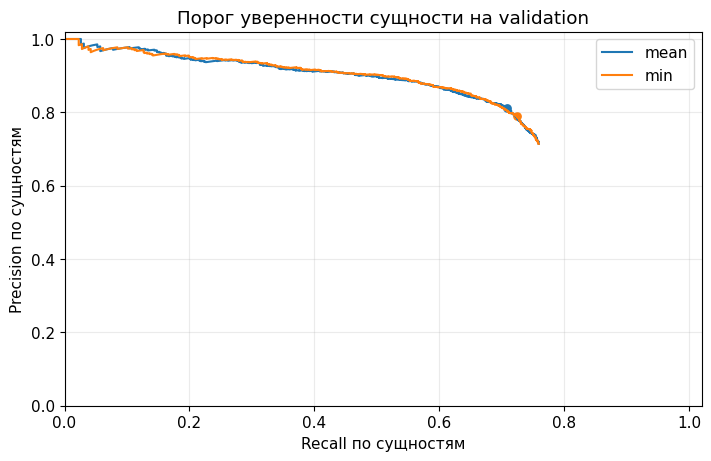

In [45]:
def collect_scored_spans(predictions, confidences, method):
    scored = []
    for tags, word_scores in zip(predictions, confidences, strict=True):
        assert len(tags) == len(word_scores)
        sentence = []
        for start, end, kind in bio_to_spans(tags):
            values = word_scores[start:end]
            confidence = min(values) if method == 'min' else sum(values) / len(values)
            sentence.append(((start, end, kind), confidence))
        scored.append(sentence)
    return scored


def span_threshold_curve(gold, scored):
    # Совпадение точно по позиции и типу. Спаны разных предложений учитываются отдельно.
    expected = [set(bio_to_spans(tags)) for tags in gold]
    n_gold = sum(map(len, expected))
    matches = [(confidence, span in gold_spans)
               for sentence, gold_spans in zip(scored, expected, strict=True)
               for span, confidence in sentence]
    matches.sort(key=lambda row: row[0], reverse=True)

    tp = total = 0
    curve = [dict(threshold=math.nextafter(1.0, math.inf), precision=0.0, recall=0.0, f1=0.0, kept=0)]
    for threshold, group in groupby(matches, key=lambda row: row[0]):
        for _, is_correct in group:
            total += 1
            tp += is_correct
        curve.append(dict(threshold=threshold, precision=tp / total,
                          recall=tp / n_gold if n_gold else 0.0,
                          f1=2 * tp / (n_gold + total), kept=total))
    if curve[-1]['threshold'] != 0:
        curve.append(dict(curve[-1], threshold=0.0))
    return curve


if '6.5' in BONUS_TASKS:
    tags, confidences = predict_word_tags(model, val_tokens, return_probs=True)
    scored_baseline_f1 = entity_scores(val_gold, tags)['f1_micro']
    threshold_results = {}
    fig, ax = plt.subplots(figsize=(7, 4.5), layout='constrained')
    for method in ('mean', 'min'):
        scored = collect_scored_spans(tags, confidences, method)
        curve = span_threshold_curve(val_gold, scored)
        base = curve[-1]
        best = max(curve, key=lambda point: (point['f1'], point['recall'], -point['threshold']))
        assert abs(base['f1'] - scored_baseline_f1) < 1e-9
        filtered = [spans_to_bio([span for span, score in sentence if score >= best['threshold']], len(words))
                    for words, sentence in zip(val_tokens, scored, strict=True)]
        assert abs(entity_scores(val_gold, filtered)['f1_micro'] - best['f1']) < 1e-9
        threshold_results[method] = dict(best=best, at_zero=base, delta_f1=best['f1'] - base['f1'])
        ax.plot([p['recall'] for p in curve], [p['precision'] for p in curve], label=method)
        ax.scatter(best['recall'], best['precision'], s=28)
        display(Markdown(
            f'**{method}** — лучший порог **{best["threshold"]:.4f}**, '
            f'entity micro-F1 **{best["f1"]:.4f}**, изменение к порогу 0 '
            f'**{100 * (best["f1"] - base["f1"]):+.2f} п. п.**. '
            f'Precision {best["precision"]:.4f}, recall {best["recall"]:.4f}.'
        ))
    ax.set(xlabel='Recall по сущностям', ylabel='Precision по сущностям',
           title='Порог уверенности сущности на validation', xlim=(0, 1.02), ylim=(0, 1.02))
    ax.grid(alpha=0.25)
    ax.legend()
    plt.show()
    save_bonus_result('6.5', dict(split='validation', n_sentences=len(val_tokens), methods=threshold_results))

**Вопрос.** Какой порог дает лучший F1 и сколько он добавляет к порогу 0? Чем отличаются средняя и минимальная уверенность? Почему порог по уверенности не может поднять recall?

**Ответ:** Средняя уверенность учитывает все слова и сглаживает отдельный слабый тег. Минимальная уверенность оценивает спан по самому слабому слову, поэтому особенно чувствительна к длинным названиям. Повышение порога только удаляет целые спаны, значит число точных попаданий может остаться тем же или уменьшиться. На validation перебираем все наблюдаемые пороги, включая 0, затем показываем лучшие значения и кривые precision–recall для обеих агрегаций. Найденные пороги оценены на том же validation, где были выбраны.

In [46]:
if BONUS_TASKS:
    assert set(bonus_results) == BONUS_TASKS, f'Без результатов: {sorted(BONUS_TASKS - set(bonus_results))}'
    print('Выполнены бонусы:', ', '.join(sorted(bonus_results)))
    print(ARTIFACTS / 'metrics.json')
    print(ARTIFACTS / 'bonus_metrics.json')

Выполнены бонусы: 6.2, 6.3, 6.4, 6.5
artifacts/metrics.json
artifacts/bonus_metrics.json
